<!-- d2l:prose id=tokenizers-md-1 fw=all -->

# Tokenizers at Scale

<!-- For maintainers. Plan: docs/llm/language_models_part_plan.md, "3.6
Tokenizers at Scale"; blueprint docs/llm/blueprints/ch03_data.md, section
3.6. The reference tokenizer and the shard format (tab_lm_tok_shard_format)
are one-way doors that the next chapter reads; chapter spec part 1.6 is
normative. Rights: Belebele (CC BY-SA 4.0) is downloaded from its pinned
commit and never re-hosted; the slice and the shards are FineWeb-2 and
FineWeb-Edu text (ODC-By). Every sentence that quotes a small-LM or
extension result says that it is at T1 scale. Extension recipe: author
ruling R4 (2026-11-20); open for the author: the body-rate rule (the
largest rate at which the control stays within 1% of its start) was chosen
after the probe's grid. fig_lm_unigram_viterbi waits for its generator. -->

Every model in this part reads text through a tokenizer, and so far we have
taken the tokenizer as given. that section built one, a
byte-level BPE, and noticed in passing that it treats languages unequally:
GPT-2's tokenizer spent about seven tokens on a Greek word where an English
word needed one. That looked like a curiosity of an old tokenizer. It is
more than that, because a language model counts everything in tokens. A
language that needs three times the tokens for the same text costs three
times the compute to train on and to serve, and fits a third as much into
the context window. Below, the same passages in ten languages go through
four released tokenizers, and under all but the newest of them the Hindi
version of a passage needs several times the tokens of the English one.

Recall how that tokenizer works. Byte-level BPE starts from the 256 byte
values, so that any string can be encoded, and repeatedly merges the most
frequent adjacent pair of symbols into a new symbol until the vocabulary is
full [@Sennrich.Haddow.Birch.2015; @Radford.Wu.Child.ea.2019]. A regular
expression first cuts the text into words, numbers and punctuation, so that
no merge crosses those boundaries, and a few special tokens such as
`<|endoftext|>` are reserved outside the merges.
that section measured what this does to
different scripts and to numbers.

This section asks four questions that the builders of a model must answer
before its first training step. Is merging the only way to build a
vocabulary? It is not: the unigram model gives every piece a probability
and segments text by maximizing it. What does the text a tokenizer is
trained on do to each language? How large should the vocabulary be? The
answer is a question of compute, with a short derivation. And can a trained
model's vocabulary be changed afterwards? At the end we freeze the
tokenizer that the rest of this part uses and write the token files that
the next chapter trains on. A tokenizer is the one component of a language
model that cannot be changed cheaply once a model has been trained on it,
so these choices deserve more thought than they usually get.

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

In [2]:
import collections
import copy
import gzip
import hashlib
import itertools
import json
import os
import shutil
import tempfile
import textwrap
import time
import unicodedata
import warnings
import pandas as pd
import regex
import sentencepiece as spm
import tiktoken
import transformers
from scipy.interpolate import PchipInterpolator
from torch.utils.checkpoint import checkpoint

<!-- d2l:prose id=tokenizers-md-2 fw=all -->

Most of this section runs on a CPU. Two experiments need a GPU: six small
language models that compare tokenizers, and eight runs that extend the
vocabulary of a released model. A normal build reads their registered
results, checks that they match this build's tokenizers, text and
configuration, and repeats part of each. Both are small, at what this
chapter calls T1 scale, and the cell below prints what that means.

In [3]:
LANGS = ('eng_Latn', 'deu_Latn', 'rus_Cyrl', 'arb_Arab', 'hin_Deva',
         'cmn_Hani', 'jpn_Jpan', 'tha_Thai', 'swh_Latn', 'kor_Hang')
BELEBELE = {l: 'zho_Hans' if l == 'cmn_Hani' else l for l in LANGS}
V_SMALL = 16_384            # the small tokenizers' vocabulary
ALPHAS = (1.0, 0.3, 0.0)     # language weighting of tokenizer text
TOK_PROXY = d2l.ProxyCfg(num_hiddens=256, num_heads=4, num_blks=4,
                         seq_len=512, vocab_size=V_SMALL)
SEEDS, LOG_EVERY, LIVE_TOKENS = (0, 1), 4, 2**19
LM_EPOCHS = 1.0              # passes of each small LM over its 45 MB
EXT_MODEL, N_NEW = 'Qwen/Qwen3-0.6B-Base', 4_096
EXT_TRAIN = dict(embed_steps=50, embed_lr=3e-3, lr=1e-5, warmup=10,
                 steps=150, batch=8, micro_batch=4, seq_len=1024,
                 eval_at=(0, 25, 50, 100, 150), seeds=(0, 1),
                 loss_chunk=1024, final_lr_frac=0.1, curve_docs=100,
                 pool_tokens=2**22)
N_TOK_DOCS, R2_VOCAB = 80_000, 32_768  # the reference tokenizer
ARTIFACTS = {  # name: (registered key, file a regeneration writes)
    'tok-lm': ('lm-data-tok-results-v1', 'tok-lm.json'),
    'tok-extend': ('lm-data-tok-results-v1', 'tok-extend.json')}
RERUN = d2l.lm_rerun(ARTIFACTS)
GPU = torch.cuda.is_available()
assert GPU or not RERUN, 'the regenerations train on a GPU'
assert GPU or not os.environ.get('CUDA_VISIBLE_DEVICES'), (
    'a GPU slot without CUDA: the small CPU path must not be captured')
SMALL = not GPU  # the CPU path: step-0 diagnostics on fewer texts
DEVICE = d2l.try_gpu()
N_EXT = (dict(hindi=8, passages=24, english=8, contexts=4, ctx_len=256)
         if SMALL else dict(hindi=500, passages=488, english=200,
                            contexts=200, ctx_len=1024))
RERUN_DIR = os.path.join('..', 'data', 'lm', 'rerun')

def say(*args, sep=' '):
    """print, each line wrapped to the page's 100 columns."""
    print('\n'.join(l if len(l) <= 100 else textwrap.fill(
        l, 100, subsequent_indent='    ', break_long_words=False,
        break_on_hyphens=False) for l in sep.join(map(str, args)).split('\n')))

with torch.device('meta'):
    N_PARAMS = d2l.num_params(d2l._proxy_model(TOK_PROXY))
TIER_LM = f'{N_PARAMS / 1e6:.1f}M-parameter LMs, one epoch over 45 MB'
TIER_EXT = (f'{EXT_MODEL.split("/")[1]}, {EXT_TRAIN["steps"]} steps of '
            f'{EXT_TRAIN["batch"]} x {EXT_TRAIN["seq_len"]:,} tokens')
TIER = f'at T1 scale ({TIER_LM}; {TIER_EXT})'  # registered with the runs
TIER_LM, TIER_EXT = (f'at T1 scale ({t})' for t in (TIER_LM, TIER_EXT))
say(f'small-LM comparison and extension {TIER.replace(" scale", "")}')
say(f'GPU={GPU}, SMALL={SMALL}, regenerating:',
    ', '.join(sorted(RERUN)) or 'none')

small-LM comparison and extension at T1 (7.3M-parameter LMs, one epoch over 45 MB; Qwen3-0.6B-Base,
    150 steps of 8 x 1,024 tokens)
GPU=True, SMALL=False, regenerating: none


<!-- d2l:prose id=tokenizers-md-3 fw=all -->

The parallel passages are those of the Belebele reading-comprehension
benchmark (CC BY-SA 4.0), downloaded from a pinned commit and never
re-hosted. The ten-language slice is FineWeb-2 text for nine languages and
FineWeb-Edu text for English [@Penedo.Kydlicek.BenAllal.ea.2024], both
ODC-By: about 4.5 MB of training text per language with a tenth held out,
plus 30,500 Hindi documents for the extension experiment. The reference
tokenizer and its shards were built once by `tools/build_r2_shards.py`;
this notebook reads and checks them. The results of both GPU experiments
sit in one registered file, `lm-data-tok-results-v1`.

In [4]:

d2l.DATA_HUB['belebele-eng_Latn'] = (  # FLORES passages, CC BY-SA 4.0
    'https://huggingface.co/datasets/facebook/belebele/resolve/'
    '7899cdfa4e1e0d733fd77c848e2c273cb1d32be2/data/eng_Latn.jsonl',
    '39c6796587fef3057a50ff60ecfa3d99c65ada99')
d2l.DATA_HUB['belebele-deu_Latn'] = (
    'https://huggingface.co/datasets/facebook/belebele/resolve/'
    '7899cdfa4e1e0d733fd77c848e2c273cb1d32be2/data/deu_Latn.jsonl',
    '2492011aa4718237cfaf71256150acb453184401')
d2l.DATA_HUB['belebele-rus_Cyrl'] = (
    'https://huggingface.co/datasets/facebook/belebele/resolve/'
    '7899cdfa4e1e0d733fd77c848e2c273cb1d32be2/data/rus_Cyrl.jsonl',
    '9c17bbd2594ec9ea831ad887587a4a401f80c48d')
d2l.DATA_HUB['belebele-arb_Arab'] = (
    'https://huggingface.co/datasets/facebook/belebele/resolve/'
    '7899cdfa4e1e0d733fd77c848e2c273cb1d32be2/data/arb_Arab.jsonl',
    'd409a6fda63a97566583558886f0414c8edd152a')
d2l.DATA_HUB['belebele-hin_Deva'] = (
    'https://huggingface.co/datasets/facebook/belebele/resolve/'
    '7899cdfa4e1e0d733fd77c848e2c273cb1d32be2/data/hin_Deva.jsonl',
    'e7017e822412dd49ef24f24419bc3e2e45175285')
d2l.DATA_HUB['belebele-zho_Hans'] = (
    'https://huggingface.co/datasets/facebook/belebele/resolve/'
    '7899cdfa4e1e0d733fd77c848e2c273cb1d32be2/data/zho_Hans.jsonl',
    'f7da1fed3c0c6d7e43a324bf8739231f2b346b6e')
d2l.DATA_HUB['belebele-jpn_Jpan'] = (
    'https://huggingface.co/datasets/facebook/belebele/resolve/'
    '7899cdfa4e1e0d733fd77c848e2c273cb1d32be2/data/jpn_Jpan.jsonl',
    '2a3755b2eaea864e066f4414c3f64e0a53cca41a')
d2l.DATA_HUB['belebele-tha_Thai'] = (
    'https://huggingface.co/datasets/facebook/belebele/resolve/'
    '7899cdfa4e1e0d733fd77c848e2c273cb1d32be2/data/tha_Thai.jsonl',
    '4aae5d586fe29db59bf12bfcbc9b75e816ca4380')
d2l.DATA_HUB['belebele-swh_Latn'] = (
    'https://huggingface.co/datasets/facebook/belebele/resolve/'
    '7899cdfa4e1e0d733fd77c848e2c273cb1d32be2/data/swh_Latn.jsonl',
    '1c327092d52031a5d7dfffe5b7419e0f2f584bc8')
d2l.DATA_HUB['belebele-kor_Hang'] = (
    'https://huggingface.co/datasets/facebook/belebele/resolve/'
    '7899cdfa4e1e0d733fd77c848e2c273cb1d32be2/data/kor_Hang.jsonl',
    '17fa36b78cef39784d497a7cf40caf678e83c955')
d2l.DATA_HUB['lm-data-fw2-slice-v1'] = (  # FineWeb-2, FineWeb-Edu: ODC-By
    d2l.LM_DATA_URL + 'lm-data-fw2-slice-v1.tar',
    '80ddb29c077df2fa73fb85f45197e32459ba4f56')
d2l.DATA_HUB['lm-r2-tokenizer-v1'] = (  # the reference tokenizer
    d2l.LM_DATA_URL + 'lm-r2-tokenizer-v1.json',
    '4e8dbe43379e205000c68cbec6798278761a38cd')
d2l.DATA_HUB['lm-fwedu-val-v1'] = (  # FineWeb-Edu validation shard: ODC-By
    d2l.LM_DATA_URL + 'lm-fwedu-val-v1.tar',
    '2675d35e9e0fb6a8e5b287c3928f5c014a8a34ab')
d2l.DATA_HUB['lm-fwedu-shards-100m-v1'] = (  # train-00000: ODC-By
    d2l.LM_DATA_URL + 'lm-fwedu-shards-100m-v1.tar',
    '66992765074d705d749c304b54f06fe5586f0c0f')
d2l.DATA_HUB['lm-fwedu-manifest-4b-v1'] = (  # 40 shards under fwedu-r2-v1/
    d2l.LM_DATA_URL + 'lm-fwedu-manifest-4b-v1.json',
    '2d97947273a7df83f494ad20bbb561bfbd2b336c')
d2l.DATA_HUB['lm-data-tok-results-v1'] = (  # small LMs and extension runs
    d2l.LM_DATA_URL + 'lm-data-tok-results-v1.json',
    'b0eb51e54b42e5273dc9b17ba416f9f998531548')

SLICE_KEY, RES_KEY = 'lm-data-fw2-slice-v1', 'lm-data-tok-results-v1'
R2_KEYS = ('lm-r2-tokenizer-v1', 'lm-fwedu-val-v1',
           'lm-fwedu-shards-100m-v1', 'lm-fwedu-manifest-4b-v1')
for name, keys in (('this section', (SLICE_KEY, RES_KEY) + R2_KEYS),
                   ('upstream', ('lm-mix-runs-t1-v1',))):
    say(f'{name}: registered', ', '.join(
        k for k in keys if k in d2l.DATA_HUB) or 'none', '| pending:',
        ', '.join(k for k in keys if k not in d2l.DATA_HUB) or 'none')

def open_tar(key):
    """The folder of a registered tar, extracted afresh whenever the
    registered sha1 differs from the one stamped at the last extraction."""
    path = d2l.download_keyed(key)
    root = os.path.join(os.path.dirname(path), 'files')
    stamp, old = os.path.join(root, '.sha1'), None
    if os.path.exists(stamp):
        with open(stamp) as f:
            old = f.read()
    if old != d2l.DATA_HUB[key][1]:
        shutil.rmtree(root, ignore_errors=True)
        os.makedirs(root)
        d2l.extract(path, root)
        with open(stamp, 'w') as f:
            f.write(d2l.DATA_HUB[key][1])
    return root

def write_json(path, obj):
    with open(path, 'w', encoding='utf-8') as f:
        json.dump(obj, f, sort_keys=True, ensure_ascii=False)

ROOT = open_tar(SLICE_KEY)
SLICE = pd.read_parquet(os.path.join(ROOT, 'slice.parquet'))
HINDI = pd.read_parquet(os.path.join(ROOT, 'hindi.parquet'))
with open(os.path.join(ROOT, 'meta.json')) as f:
    SLICE_META = json.load(f)
TRAIN, HELD = ({l: SLICE[(SLICE.lang == l) & (SLICE.part == p)].text.tolist()
                for l in LANGS} for p in ('train', 'heldout'))
assert all(t == unicodedata.normalize('NFC', t) for t in SLICE.text)
RESULTS = None  # the registered results of both regenerations
if RES_KEY in d2l.DATA_HUB:
    with open(d2l.lm_artifact(RES_KEY), encoding='utf-8') as f:
        RESULTS = json.load(f)
assert RESULTS is not None or RERUN in (set(), set(ARTIFACTS)), (
    'the first generation makes both parts in one run (D2L_RERUN=1); a '
    'single part reads the other one from the registered results')
print(pd.DataFrame({
    'train docs': {l: len(TRAIN[l]) for l in LANGS},
    'train MB': {l: sum(len(t.encode()) for t in TRAIN[l]) / 1e6
                 for l in LANGS},
    'held-out docs': {l: len(HELD[l]) for l in LANGS}}).round(2))
print('Hindi extension documents:', HINDI.part.value_counts().to_dict())

this section: registered lm-data-fw2-slice-v1, lm-data-tok-results-v1, lm-r2-tokenizer-v1,
    lm-fwedu-val-v1, lm-fwedu-shards-100m-v1, lm-fwedu-manifest-4b-v1 | pending: none
upstream: registered lm-mix-runs-t1-v1 | pending: none


          train docs  train MB  held-out docs
eng_Latn         972      4.54            108
deu_Latn        1520      4.51            168
rus_Cyrl         606      4.11             67
arb_Arab         463      5.04             51
hin_Deva         785      4.51             87
cmn_Hani        1106      4.60            122
jpn_Jpan        1110      4.66            123
tha_Thai         491      4.66             54
swh_Latn        1459      4.62            162
kor_Hang        1687      4.49            187
Hindi extension documents: {'ext_train': 30000, 'ext_heldout': 500}


<!-- d2l:prose id=tokenizers-md-4 fw=all -->

that section measured a tokenizer's *fertility*
as tokens per word. Words are a poor unit across languages: Thai and
Chinese put no spaces between them, and a German compound is a single
word. Parallel text lets us do without them. Petrov and colleagues (2023)
define the *tokenization premium* of a language as the number of tokens
its version of a set of passages needs, divided by the number the English
version needs. The passages say the same thing, so a premium of 2 means
twice the compute and twice the context for the same content.
`fertility_table` also reports bytes per token and the share of tokens
that are single bytes of a multi-byte character. Such a token means that
the tokenizer had no piece for the character at all and spelled it out.

In [5]:

def fertility_table(encoders, parallel, ref='eng_Latn'):
    """Per encoder and language: passages, UTF-8 bytes, tokens, bytes per
    token, tokens per passage, the share of byte-fallback tokens and the
    premium, the tokens a language needs over the tokens ref needs for
    translations of the same passages. encoders maps a name to encode(str)
    -> ids, or to (encode, fallback_ids); parallel maps a language to its
    passages, aligned across languages."""
    rows = []
    for name, enc in encoders.items():
        enc, fallback = enc if isinstance(enc, tuple) else (enc, ())
        fallback = set(fallback)
        for lang, passages in parallel.items():
            ids = [enc(p) for p in passages]
            n = sum(map(len, ids))
            n_bytes = sum(len(p.encode('utf-8')) for p in passages)
            rows.append(dict(
                encoder=name, lang=lang, passages=len(passages),
                bytes=n_bytes, tokens=n, bytes_per_token=n_bytes / n,
                tokens_per_passage=n / len(passages),
                fallback_share=sum(i in fallback for x in ids for i in x)
                / n))
    df = pd.DataFrame(rows)
    ref_tokens = df[df.lang == ref].set_index('encoder').tokens
    df['premium'] = df.tokens / df.encoder.map(ref_tokens)
    return df

<!-- d2l:prose id=tokenizers-md-5 fw=all -->

We compare four released tokenizers: GPT-2's (2019) and `o200k_base`
(OpenAI's tokenizer of 2024), both through `tiktoken`, and those of Qwen3
and Qwen3.5, the model family this part of the book uses, loaded from
pinned revisions. The text is Belebele's 488 distinct passages in each of
the ten languages. (Belebele calls simplified Chinese `zho_Hans`;
FineWeb-2 calls it `cmn_Hani`.)

In [6]:
def belebele(lang):
    """The distinct passages of a Belebele language by link (a passage's
    link is the same in every language)."""
    with open(d2l.download_keyed('belebele-' + BELEBELE[lang]),
              encoding='utf-8') as f:
        return {r['link']: r['flores_passage'] for r in map(json.loads, f)}

def hf_tokenizer(model_id):
    return transformers.AutoTokenizer.from_pretrained(
        model_id, revision=d2l.HF_REVISIONS[model_id])

def encoder(tok):
    """(encode, fallback ids) of any tokenizer the section uses; special
    strings in a text stay text."""
    if hasattr(tok, 'encode_as_ids'):  # SentencePiece
        return tok.encode, d2l._fallback_ids(tok)
    return (lambda s: d2l._doc_token_ids(tok, [s])[0],
            d2l._fallback_ids(tok))

by_link = {lang: belebele(lang) for lang in LANGS}
LINKS = sorted(by_link['eng_Latn'])
assert all(sorted(p) == LINKS for p in by_link.values())
BELE = {lang: [p[k] for k in LINKS] for lang, p in by_link.items()}
RELEASED = {'GPT-2': tiktoken.get_encoding('gpt2'),
            'o200k_base': tiktoken.get_encoding('o200k_base'),
            'Qwen3': hf_tokenizer('Qwen/Qwen3-0.6B-Base'),
            'Qwen3.5': hf_tokenizer('Qwen/Qwen3.5-0.8B-Base')}
FERT = d2l.fertility_table({k: encoder(t) for k, t in RELEASED.items()},
                           BELE)
say(f'{len(LINKS)} passages per language')
say(FERT.pivot(index='lang', columns='encoder', values='premium')
    .loc[list(LANGS)].round(2))
say(FERT.pivot(index='lang', columns='encoder', values='bytes_per_token')
    .loc[list(LANGS)].round(2))
say(FERT.pivot(index='lang', columns='encoder', values='fallback_share')
    .loc[list(LANGS)].round(3))
PREM = FERT.set_index(['encoder', 'lang']).premium
# C1: English-centred tokenizers charge non-Latin scripts several times
assert min(PREM['GPT-2', l] for l in ('hin_Deva', 'tha_Thai')) > 3
assert PREM['Qwen3.5', 'hin_Deva'] < PREM['Qwen3', 'hin_Deva']
say(f"Hindi premium: Qwen3 {PREM['Qwen3', 'hin_Deva']:.1f}, "
    f"Qwen3.5 {PREM['Qwen3.5', 'hin_Deva']:.1f}")

488 passages per language
encoder   GPT-2  Qwen3  Qwen3.5  o200k_base
lang                                       
eng_Latn   1.00   1.00     1.00        1.00
deu_Latn   2.14   1.56     1.31        1.31
rus_Cyrl   5.74   1.77     1.37        1.43
arb_Arab   4.39   1.63     1.30        1.38
hin_Deva   7.43   4.45     2.01        1.56
cmn_Hani   3.20   1.06     0.95        1.28
jpn_Jpan   2.99   1.44     1.18        1.68
tha_Thai   9.00   2.57     1.21        1.95
swh_Latn   2.13   1.93     1.82        1.48
kor_Hang   5.06   1.64     1.23        1.47
encoder   GPT-2  Qwen3  Qwen3.5  o200k_base
lang                                       
eng_Latn   4.91   4.82     4.83        4.95
deu_Latn   2.72   3.67     4.37        4.49
rus_Cyrl   1.71   5.44     7.03        6.88
arb_Arab   1.79   4.72     5.94        5.74
hin_Deva   1.69   2.76     6.14        8.07
cmn_Hani   1.42   4.20     4.70        3.58
jpn_Jpan   2.09   4.23     5.19        3.74
tha_Thai   1.50   5.15    10.99        6.97
swh_La

<!-- d2l:prose id=tokenizers-md-6 fw=all -->

GPT-2's tokenizer needs more than seven times English's tokens for Hindi
and nine times for Thai, and almost half of its Hindi tokens are lone
bytes. Qwen3's tokenizer, three times larger, brings Thai down to 2.6 but
leaves Hindi at 4.5, and a quarter of its Hindi tokens are still pieces of
a character. Qwen3.5's tokenizer halves the Hindi premium again, to 2.0.
Notice that Qwen3.5 reads *more* bytes per Hindi token (6.1) than per
English token (4.8) and still needs twice as many tokens. The reason is
the encoding: a Devanagari character takes three bytes in UTF-8 and a
Latin letter one, so the Hindi version of the passages is about 2.6 times
as long in bytes as the English. Part of every premium belongs to UTF-8,
and no tokenizer removes it without pieces of many bytes.

## The Unigram Model

BPE builds its vocabulary by a sequence of decisions: merge the most
frequent pair, then the next most frequent, and so on. Encoding replays
these decisions in the order they were made, so the segmentation of a word
is whatever the merge order produces. Nothing ever compares two
segmentations of the same word and asks which one is better. The *unigram
model* of Kudo (2018) asks exactly that. It gives each piece $x$ of
the vocabulary a probability $p(x)$, treats the pieces of a segmentation as
independent draws, and prefers the most probable segmentation. Training
chooses the vocabulary and the probabilities to make the corpus likely.

Let us make this precise. A segmentation $\mathbf{s} = (x_1, \ldots, x_k)$
of a word $w$ has probability $P(\mathbf{s}) = \prod_{m=1}^k p(x_m)$, and
the word has probability $P(w) = \sum_{\mathbf{s}} P(\mathbf{s})$, summed
over all its segmentations. There can be exponentially many, but they have
a simple structure. Write the word's characters at positions $0$ to $n$
and draw an edge from $i$ to $j$ whenever the substring $w_{i:j}$ is a
piece. This is the word's *lattice*. Every path from $0$ to $n$ is a
segmentation, and its probability is the product of the edge
probabilities along it. For the word *sports* (written `▁sports`, with
SentencePiece's mark of a word start) the lattice of a trained vocabulary
contains the paths `▁s|port|s` and `▁sp|ort|s`, among others.

Sums over all paths of a lattice are computed by dynamic programming. The
forward sum $f_j$ collects the probability of every path from $0$ to $j$,
and the backward sum $g_i$ that of every path from $i$ to $n$:

$$
f_0 = 1, \quad f_j = \sum_{i < j} f_i\, p(w_{i:j}), \qquad
g_n = 1, \quad g_i = \sum_{j > i} p(w_{i:j})\, g_j,
$$

where a term is zero when $w_{i:j}$ is not a piece. Then $P(w) = f_n$, and
the probability that a segmentation of $w$ uses the edge from $i$ to $j$
is the share of all paths through it, $f_i\, p(w_{i:j})\, g_j / P(w)$.

Training maximizes the log-likelihood of a corpus in which word $w$ occurs
$c_w$ times, $\sum_w c_w \log P(w)$. The segmentations are hidden, so we
use expectation-maximization. The E-step computes the expected number of
times $N_x$ that piece $x$ is used, summing the edge probabilities over
every edge labelled $x$ in every word. The M-step chooses new probabilities
that maximize $\sum_x N_x \log p(x)$ subject to $\sum_x p(x) = 1$. With a
Lagrange multiplier $\lambda$, setting the derivative of
$\sum_x N_x \log p(x) - \lambda (\sum_x p(x) - 1)$ to zero gives
$N_x / p(x) = \lambda$, so the probabilities are the expected counts,
normalized:

$$
N_x = \sum_w c_w \sum_{(i, j):\, w_{i:j} = x}
\frac{f_i\, p(w_{i:j})\, g_j}{P(w)},
\qquad
p_{\textrm{new}}(x) = \frac{N_x}{\sum_y N_y}.
$$

In words, each piece gets the probability of being used, averaged over all
the ways the corpus could have been cut. Each round of EM never lowers the
likelihood; the exercises ask you to show it.

Three more operations complete the model. *Viterbi segmentation* replaces
the sum in the forward recursion by a maximum and remembers which edge won,
which gives the most probable path in time proportional to the word's
length times the longest piece; this is `d2l.viterbi_segment`. *Pruning*
shrinks the vocabulary, which EM alone never does. Training starts from
every character and the 100,000 most frequent substrings, runs two rounds
of EM, and then removes the pieces whose removal costs the least
likelihood: a piece's loss is how often the Viterbi segmentations use it
times how much less probable its best segmentation without it is. Keeping
80% per round until the target size is reached, with every single
character kept so that each word stays segmentable, is the procedure of
`d2l.UnigramTokenizer`. Finally, because the model is probabilistic, it can
*sample* segmentations, drawing $\mathbf{s}$ with probability proportional
to $P(\mathbf{s})^{\beta}$ by running the forward recursion on
$p(x)^{\beta}$ and then drawing edges backwards from $n$. At $\beta = 0$
all segmentations are equally likely, and as $\beta \to \infty$ the sample
becomes the Viterbi path. Kudo trained translation models on a fresh
sample each time a sentence was read, so that the model sees many
segmentations of each word and cannot rely on any one of them. He called
this *subword regularization*. (The code calls $\beta$ `alpha`, Kudo's
name for it.)

<!-- Figure pending (write step CODE REQUEST): ![The segmentation lattice of one word: positions are nodes, pieces are edges labelled with their log-probabilities, and the Viterbi path is highlighted.](../img/mdl-lm-data-unigram-viterbi.svg) :label:`fig_lm_unigram_viterbi`, generated by tools/gen_mdl_lm_data_figures.py; the prose describes the lattice in words until it exists. -->

In [7]:

def _unigram_lattice(s, logp, max_len):
    """Edges (i, j, piece) of the segmentation lattice of s, by start i:
    s[i:j] is a piece of logp."""
    return [(i, j, s[i:j]) for i in range(len(s))
            for j in range(i + 1, min(len(s), i + max_len) + 1)
            if s[i:j] in logp]


def _unigram_fb(s, logp, max_len):
    """log P(s), summed over all segmentations of s, and each piece's
    posterior expected count in s (forward-backward on the lattice)."""
    n, edges = len(s), _unigram_lattice(s, logp, max_len)
    fwd, bwd = [-math.inf] * (n + 1), [-math.inf] * (n + 1)
    fwd[0] = bwd[n] = 0.0
    for i, j, x in edges:  # by start: fwd[i] is complete when read
        fwd[j] = d2l._logaddexp(fwd[j], fwd[i] + logp[x])
    for i, j, x in reversed(edges):  # by start, descending
        bwd[i] = d2l._logaddexp(bwd[i], logp[x] + bwd[j])
    counts = collections.Counter()
    for i, j, x in edges:
        counts[x] += math.exp(fwd[i] + logp[x] + bwd[j] - fwd[n])
    return fwd[n], counts


def viterbi_segment(text, logp, max_len, *, unk=None):
    """The most probable segmentation of text into pieces of logp (piece
    -> log-probability) of at most max_len characters; ties go to fewer
    pieces. With unk, a character that is no piece is a piece of
    log-probability unk (SentencePiece's rule for unknown characters)."""
    n = len(text)
    best, back = [(-math.inf, 0)] * (n + 1), [0] * (n + 1)
    best[0] = (0.0, 0)  # (log-probability, minus the number of pieces)
    for j in range(1, n + 1):
        for i in range(max(0, j - max_len), j):
            lp = logp.get(text[i:j], unk if j == i + 1 else None)
            if lp is not None and best[i][0] > -math.inf:
                cand = (best[i][0] + lp, best[i][1] - 1)
                if cand > best[j]:
                    best[j], back[j] = cand, i
    if best[n][0] == -math.inf:
        raise ValueError(f'no segmentation of {text!r}')
    out, j = [], n
    while j > 0:
        out.append(text[back[j]:j])
        j = back[j]
    return out[::-1]


def _unigram_sample(s, logp, max_len, alpha, rng):
    """A segmentation of s drawn with probability proportional to
    P(segmentation)^alpha: forward filtering, then backward sampling."""
    fwd, into = [-math.inf] * (len(s) + 1), collections.defaultdict(list)
    fwd[0] = 0.0
    for i, j, x in _unigram_lattice(s, logp, max_len):
        fwd[j] = d2l._logaddexp(fwd[j], fwd[i] + alpha * logp[x])
        into[j].append((i, x))
    out, j = [], len(s)
    while j > 0:
        w = np.array([fwd[i] + alpha * logp[x] for i, x in into[j]])
        p = np.exp(w - w.max())
        i, x = into[j][rng.choice(len(w), p=p / p.sum())]
        out.append(x)
        j = i
    return out[::-1]


class UnigramTokenizer:
    """A unigram language model over pieces (Kudo 2018), trained by EM
    with pruning: seed the vocabulary with every character and the
    seed_size most frequent substrings (scored by count times length),
    then alternate em_iters EM steps with keeping prune_frac of the pieces
    until vocab_size remain. Words are split at whitespace and marked by a
    leading U+2581, as SentencePiece marks them."""
    def __init__(self, vocab_size, seed_size=100_000, em_iters=2,
                 prune_frac=0.8, max_piece_len=12):
        self.vocab_size, self.seed_size = vocab_size, seed_size
        self.em_iters, self.prune_frac = em_iters, prune_frac
        self.max_len, self.pieces, self.history = max_piece_len, {}, []

    @staticmethod
    def _words(sentences):
        return collections.Counter('▁' + w for s in sentences
                                   for w in s.split())

    def _em_step(self, words, logp):
        """E: expected piece counts under logp; M: probabilities
        proportional to them. Returns the new log-probabilities and the
        corpus log-likelihood under the old ones."""
        counts, loglik = collections.Counter(), 0.0
        for w, c in words.items():
            logz, cw = d2l._unigram_fb(w, logp, self.max_len)
            loglik += c * logz
            for x, v in cw.items():
                counts[x] += c * v
        for x in logp:  # a character stays a piece, however rare
            if len(x) == 1 and counts[x] <= 0:
                counts[x] = 1e-6
        log_total = math.log(sum(counts.values()))
        return ({x: math.log(counts[x]) - log_total for x in logp
                 if counts[x] > 0}, loglik)

    def _prune(self, words, logp, keep):
        """The keep pieces whose removal costs the most likelihood: a
        piece's loss is its count in the Viterbi segmentations times what
        its log-probability gains over the best segmentation of its own
        string without it. Characters are always kept."""
        freq = collections.Counter()
        for w, c in words.items():
            for x in d2l.viterbi_segment(w, logp, self.max_len):
                freq[x] += c
        loss, others = {}, dict(logp)
        for x, lp in logp.items():
            if len(x) > 1:
                del others[x]
                alt = d2l.viterbi_segment(x, others, self.max_len)
                loss[x] = freq[x] * (lp - sum(others[a] for a in alt))
                others[x] = lp
        chars = [x for x in logp if len(x) == 1]
        ranked = sorted(loss, key=lambda x: (-loss[x], x))
        kept = set(chars) | set(ranked[:max(keep - len(chars), 0)])
        return {x: lp for x, lp in logp.items() if x in kept}

    def train(self, sentences):
        words = self._words(sentences)
        subs, chars = collections.Counter(), collections.Counter()
        for w, c in words.items():
            for i in range(len(w)):
                chars[w[i]] += c
                for j in range(i + 2, min(len(w), i + self.max_len) + 1):
                    subs[w[i:j]] += c
        seed = sorted(subs, key=lambda x: (-subs[x] * len(x), x))
        seed = {x: subs[x] * len(x) for x in seed[:self.seed_size]}
        seed.update(chars)
        total = sum(seed.values())
        logp = {x: math.log(v / total) for x, v in seed.items()}
        while True:
            for _ in range(self.em_iters):
                logp, loglik = self._em_step(words, logp)
                self.history.append((len(logp), loglik))
            if len(logp) <= self.vocab_size:
                break
            logp = self._prune(words, logp, max(
                self.vocab_size, int(len(logp) * self.prune_frac)))
        self.pieces = logp
        return self

    def encode(self, text):
        return [x for w in text.split() for x in d2l.viterbi_segment(
            '▁' + w, self.pieces, self.max_len)]

    def encode_sample(self, text, alpha=0.2, seed=0):
        """A segmentation drawn with probability proportional to
        P(segmentation)^alpha, word by word (subword regularization)."""
        rng = np.random.default_rng(seed)
        return [x for w in text.split() for x in d2l._unigram_sample(
            '▁' + w, self.pieces, self.max_len, alpha, rng)]

<!-- d2l:prose id=tokenizers-md-7 fw=all -->

Every step of this derivation can be checked by brute force on short
strings over the alphabet $\{a, b, c\}$, where all segmentations can be
listed. The cell compares the forward sum and the expected counts with
their values over the enumerated segmentations, Viterbi with the best
enumerated segmentation, each round of EM with the previous one, and the
frequencies of sampled segmentations with their probabilities.

In [8]:
def segmentations(s, logp, max_len):
    """Every segmentation of s into pieces of logp (brute force)."""
    if not s:
        yield []
        return
    for j in range(1, min(max_len, len(s)) + 1):
        if s[:j] in logp:
            for rest in segmentations(s[j:], logp, max_len):
                yield [s[:j]] + rest

def random_pieces(rng, n=12, max_len=4):
    pieces = set('abc') | {''.join(rng.choice(list('abc'), k)) for k in
                           rng.integers(2, max_len + 1, n)}
    w = rng.random(len(pieces))
    return dict(zip(sorted(pieces), np.log(w / w.sum())))

rng, err, ties = np.random.default_rng(0), 0.0, 0
for _ in range(200):  # forward-backward and Viterbi against enumeration
    logp = random_pieces(rng)
    s = ''.join(rng.choice(list('abc'), rng.integers(1, 13)))
    segs = list(segmentations(s, logp, 4))
    lps = np.array([sum(logp[x] for x in g) for g in segs])
    logz, counts = d2l._unigram_fb(s, logp, 4)
    brute = collections.Counter()
    for g, lp in zip(segs, lps):
        for x in g:
            brute[x] += math.exp(lp - np.logaddexp.reduce(lps))
    err = max(err, abs(logz - np.logaddexp.reduce(lps)),
              *(abs(brute[x] - counts[x]) for x in set(brute) | set(counts)))
    v = d2l.viterbi_segment(s, logp, 4)
    top = [len(g) for g, lp in zip(segs, lps) if lp >= lps.max() - 1e-12]
    ties += len(top) > 1
    assert ''.join(v) == s and len(v) == min(top)
    assert sum(logp[x] for x in v) >= lps.max() - 1e-12
assert err < 1e-9
say(f'forward-backward vs enumeration: max difference {err:.1e}; '
    f'Viterbi = argmax on 200 strings ({ties} with tied maxima)')

toy = [''.join(rng.choice(list('abc'), rng.integers(3, 9)))
       for _ in range(5000)]
uni = d2l.UnigramTokenizer(vocab_size=0, max_piece_len=3)
words = collections.Counter(toy)
logp = random_pieces(np.random.default_rng(1), n=20, max_len=3)
lls = []
for _ in range(6):  # EM never lowers the corpus log-likelihood
    logp, ll = uni._em_step(words, logp)
    lls.append(ll)
assert all(b >= a - 1e-9 for a, b in zip(lls, lls[1:]))
say('EM log-likelihood:', ', '.join(f'{ll:,.1f}' for ll in lls))

s, alpha = 'abcabc', 0.2  # sampled segmentations against posteriors
logp = random_pieces(np.random.default_rng(2), n=40)
segs = [tuple(g) for g in segmentations(s, logp, 4)]
w = alpha * np.array([sum(logp[x] for x in g) for g in segs])
post = dict(zip(segs, np.exp(w - np.logaddexp.reduce(w))))
draws, rng = 10_000, np.random.default_rng(0)
freq = collections.Counter(tuple(d2l._unigram_sample(s, logp, 4, alpha, rng))
                           for _ in range(draws))
z = max(abs(freq[g] / draws - p) / math.sqrt(p * (1 - p) / draws)
        for g, p in post.items())
assert z < 3
say(f'{len(segs)} segmentations of {s!r}: sampled frequencies within '
    f'{z:.1f} standard errors of their posteriors')

forward-backward vs enumeration: max difference 2.5e-14; Viterbi = argmax on 200 strings (4 with
    tied maxima)


EM log-likelihood: -38,093.2, -33,945.1, -33,167.4, -32,760.7, -32,469.2, -32,229.6
7 segmentations of 'abcabc': sampled frequencies within 2.4 standard errors of their posteriors


<!-- d2l:prose id=tokenizers-md-8 fw=all -->

Forward-backward agrees with enumeration to rounding error, the
log-likelihood rises at every round of EM, and 10,000 samples of the seven
segmentations of `abcabc` land within 2.4 standard errors of their
probabilities. Four of the 200 random strings have two best segmentations
of equal probability; Viterbi then takes the one with fewer pieces.

Now a real vocabulary. We train `UnigramTokenizer` to 4,096 pieces on
1 MB of English from the slice, and the unigram trainer of SentencePiece,
the production implementation (Kudo and Richardson, 2018), on the same
text. Then we load SentencePiece's pieces and scores into our
`viterbi_segment` and ask whether it reproduces SentencePiece's
segmentation of 1,000 held-out lines. SentencePiece marks a word start
with ▁ (U+2581) attached to the following piece and spells a character
that has no piece by its UTF-8 bytes (`byte_fallback`); `sp_viterbi`
imitates both. The cell also lists words whose two best segmentations are
close and samples five segmentations of one sentence at $\beta = 0.2$.

In [9]:
def first_bytes(texts, n_bytes):
    """Documents in order until n_bytes UTF-8 bytes."""
    out, b = [], 0
    for t in texts:
        if b >= n_bytes:
            break
        out.append(t)
        b += len(t.encode('utf-8'))
    return out

def lines(texts):
    return [l for t in texts for l in t.split('\n') if l.strip()]

eng_1mb = first_bytes(TRAIN['eng_Latn'], 1_000_000)
held_lines = lines(HELD['eng_Latn'])[:1000]
tic = time.time()
uni = d2l.UnigramTokenizer(4096).train(lines(eng_1mb))
t_ours = time.time() - tic
tic = time.time()
sp_uni = d2l.sp_train(eng_1mb, 'unigram', 4096)
t_sp = time.time() - tic
say(f'from scratch: {len(uni.pieces):,} pieces in {t_ours:.0f} s '
    f'({len(uni.history) // uni.em_iters} rounds); SentencePiece: '
    f'{t_sp:.1f} s')

def sp_viterbi(sp, text):
    """SentencePiece's segmentation recomputed by viterbi_segment from its
    pieces and scores: spaces become U+2581 (with the dummy prefix), a
    character that is no piece is spelled by its byte pieces."""
    logp, unk = d2l._sp_pieces_scores(sp)
    s = '▁' + text.replace(' ', '▁')
    out = []
    for x in d2l.viterbi_segment(s, logp, 16, unk=unk):
        out += ([x] if x in logp else
                [f'<0x{b:02X}>' for b in x.encode('utf-8')])
    return out

same = [sp_viterbi(sp_uni, l) == sp_uni.encode(l, out_type=str)
        for l in held_lines]
say(f'viterbi_segment reproduces SentencePiece on {sum(same)} of '
    f'{len(same)} held-out lines')
for l, ok in list(zip(held_lines, same)):
    if not ok:  # the first disagreements and their cause
        a, b = sp_viterbi(sp_uni, l), sp_uni.encode(l, out_type=str)
        k = next(i for i, (x, y) in enumerate(zip(a, b)) if x != y)
        say('  ours', a[k:k + 4], '| SentencePiece', b[k:k + 4])
assert sum(same) >= 0.99 * len(same)  # C2

logp_sp, _ = d2l._sp_pieces_scores(sp_uni)
shared = set(uni.pieces) & set(logp_sp)
say(f'vocabulary overlap: {len(shared):,} of {len(uni.pieces):,} pieces '
    f'({len(shared) / len(uni.pieces):.0%})')
two = []  # frequent words whose two best segmentations are close
for w, _ in d2l.UnigramTokenizer._words(held_lines).most_common():
    if not 7 <= len(w) <= 13:
        continue
    segs = sorted(((sum(uni.pieces[x] for x in g), g) for g in
                   segmentations(w, uni.pieces, 12)), reverse=True)[:2]
    if len(segs) == 2 and segs[0][0] - segs[1][0] < 1.0:
        two.append((w, segs))
    if len(two) == 5:
        break
for w, segs in two:
    say(w, ' | '.join(f'{" ".join(g)} ({lp:.1f})' for lp, g in segs))
sentence = held_lines[0][:80]
say('Viterbi:', ' '.join(uni.encode(sentence)))
for seed in range(5):
    say(f'sample {seed}:', ' '.join(uni.encode_sample(sentence, 0.2, seed)))

from scratch: 4,096 pieces in 65 s (16 rounds); SentencePiece: 1.5 s


viterbi_segment reproduces SentencePiece on 1000 of 1000 held-out lines
vocabulary overlap: 3,067 of 4,096 pieces (75%)
▁Diabetes ▁D ia b et es (-33.3) | ▁D ia be t es (-33.4)
▁sports ▁s port s (-18.5) | ▁sp ort s (-19.3)
▁poverty ▁p over ty (-22.8) | ▁po ver ty (-23.8)
▁Portuguese ▁P ort u gue se (-37.3) | ▁P ort u gue s e (-38.0)
▁Hebrew ▁He b re w (-26.7) | ▁He b r ew (-27.2)
Viterbi: ▁Since ▁2002 , ▁when ▁H A V A ▁was ▁en ac ted , ▁computer ▁scientists ▁have ▁release d
    ▁over ▁three
sample 0: ▁Since ▁2002 , ▁when ▁H A V A ▁was ▁en a ct ed , ▁ com p u ter ▁scientists ▁have ▁ r e l e
    a s ed ▁ over ▁three
sample 1: ▁Since ▁2002 , ▁w he n ▁H A V A ▁w as ▁en a ct ed , ▁computer ▁scientists ▁have ▁release d
    ▁over ▁t h r e e
sample 2: ▁Since ▁ 200 2 , ▁when ▁H A V A ▁was ▁ en ac t ed , ▁comp u ter ▁scientists ▁have ▁re l ea
    se d ▁ over ▁three
sample 3: ▁Since ▁20 0 2 , ▁when ▁H A V A ▁was ▁en a c t ed , ▁comp u ter ▁scientists ▁h av e
    ▁release d ▁over ▁t h re e
sample 4

<!-- d2l:prose id=tokenizers-md-9 fw=all -->

Our pure-Python trainer needs about a minute where SentencePiece's C++
needs a second or two, but the model is the same: Viterbi on
SentencePiece's pieces and scores reproduces every one of its 1,000
segmentations. The two trainers agree on three quarters of their pieces
(3,067 of 4,096). They seed and prune differently, and the pieces they
disagree on are rare ones whose fate was close. The word list shows what a
probabilistic lexicon has that a merge table lacks. For *sports* the two
best paths are `▁s|port|s` and `▁sp|ort|s`, with log-probabilities $-18.5$
and $-19.3$ nats, so the first is $e^{0.8} \approx 2.2$ times as probable as
the second. At $\beta = 0.2$ the ratio shrinks to $e^{0.16} \approx 1.17$,
nearly a coin toss. That is why the sampled segmentations of the sentence,
a held-out FineWeb-Edu line (ODC-By), look so ragged: *three* stays whole
in three samples and falls apart in the other two, and even *Since* is
spelled out once. A model trained on such samples has to recognize a word
however it is cut.

Two defaults of SentencePiece change the text a model sees, and neither
says so. Its default normalization, `nmt_nfkc`, applies Unicode's
compatibility folding: ligatures become letters, superscripts become
digits, full-width forms become ASCII. That is convenient for machine
translation and wrong for a pretraining corpus, in which $x^2$ and x2 are
different things. The notebook normalizes every text to NFC itself, which
only composes accents with their letters, and tells SentencePiece to leave
the text alone. The second default, `character_coverage` of 0.9995, leaves
out of the vocabulary the rarest characters that together make up 0.05% of
the training text; byte fallback then spells them in bytes.

In [10]:
probe = ['ﬁnance', 'x² + y²', 'ＡＢＣ１２',
         'café', 'Ⅳ ①']
nfkc = spm.SentencePieceNormalizer(rule_name='nmt_nfkc')
say(pd.DataFrame({'text': probe,
                  'nmt_nfkc': [nfkc.normalize(s) for s in probe],
                  'changed': [nfkc.normalize(s) != s for s in probe]}))
jpn = first_bytes(TRAIN['jpn_Jpan'], 1_000_000)
rows = {}
for cov in (0.9995, 1.0):
    sp = d2l.sp_train(jpn, 'unigram', 4096, character_coverage=cov)
    fb = d2l._fallback_ids(sp)
    ids = [i for p in BELE['jpn_Jpan'] for i in sp.encode(p)]
    chars = {p for p in d2l._sp_pieces_scores(sp)[0] if len(p) == 1}
    rows[cov] = dict(single_characters=len(chars),
                     fallback_share=sum(i in fb for i in ids) / len(ids),
                     tokens=len(ids))
say(pd.DataFrame(rows).T.round(4).rename_axis('character_coverage'))

      text nmt_nfkc  changed
0   ﬁnance  finance     True
1  x² + y²  x2 + y2     True
2    ＡＢＣ１２    ABC12     True
3     café     café    False
4      Ⅳ ①     IV 1     True


                    single_characters  fallback_share   tokens
character_coverage                                            
0.9995                         2523.0          0.0135  75365.0
1.0000                         2707.0          0.0096  75988.0


<!-- d2l:prose id=tokenizers-md-10 fw=all -->

Four of the five probe strings change under `nmt_nfkc`; only *café*,
already composed, survives. On Japanese, full coverage keeps 2,707 single
characters as pieces and the default 2,523. The default spells more of the
Belebele text in bytes (1.35% of tokens against 0.96%) and yet needs 0.8%
fewer tokens in all, because the 184 slots freed from rare characters go
to longer pieces of common text. That is what coverage below 1 is for, and
it is a choice to make on purpose.

The unigram model and BPE produce the same kind of object, a list of
pieces, and both encode a word as a sequence of pieces. They differ in the
rule that chooses the sequence. BPE replays its merges in the order it
learned them. The unigram model picks the most probable segmentation and
can sample others. In the rest of this section the more consequential
differences are not between these two algorithms but between what any
tokenizer does to different languages.

## The Tokenization Premium

A tokenizer is a compressor fitted to its training text. Frequent strings
become single pieces, and rare strings are spelled from smaller ones. A
language that is rare in that text therefore gets few pieces and many
tokens. Released tokenizers are usually trained on a sample of the model's
pretraining data, in which English dominates, so the premium of the
opening is partly a choice of training text. We can test this directly
with the temperature weighting of that section,
which samples a source with $n_i$ documents in proportion to $n_i^\alpha$:
at $\alpha = 1$ in proportion to size, at $\alpha = 0$ uniformly. We train
three byte-level BPEs of 16,384 pieces on the ten-language slice, with the
languages weighted at $\alpha = 1$, $0.3$ and $0$ according to FineWeb-2's
document counts. FineWeb-2 has no English, so English is given German's
count, so that at $\alpha = 1$ it weighs as one large European language
among others. (that section uses FineWeb's English count
instead, about fifty times German's, which at $\alpha = 1$ would hand
English about nine tenths of the tokenizer's text.) The most heavily
weighted language contributes all of its 4.5 MB of training text and the
others proportionally less.

These three tokenizers, and the reference tokenizer later in the section,
are built with the Hugging Face `tokenizers` library, which assembles a
tokenizer from four parts: a normalizer (here NFC), a pre-tokenizer (the
split rule, then a map from bytes to printable symbols), a model (BPE) and
a decoder that undoes the byte map. The split rule, `R2_SPLIT_REGEX`, is
Qwen3's. It matches contractions, runs of letters with at most one leading
non-letter, single digits, runs of punctuation, newlines and whitespace.
`train_hf_bpe` builds this pipeline for any vocabulary size and list of
special tokens, which take the first ids.

In [11]:

R2_SPLIT_REGEX = (r"""(?i:'s|'t|'re|'ve|'m|'ll|'d)|[^\r\n\p{L}\p{N}]?\p{L}+"""
                  r"""|\p{N}| ?[^\s\p{L}\p{N}]+[\r\n]*|\s*[\r\n]+|\s+(?!\S)"""
                  r"""|\s+""")


def train_hf_bpe(texts, vocab_size, specials, regex=R2_SPLIT_REGEX,
                 min_frequency=2):
    """A byte-level BPE (Hugging Face tokenizers) trained on texts: NFC,
    the split regex, bytes as 256 base symbols, the special tokens first
    (ids 0, 1, ...), no BOS or EOS added on encode. Special-token strings
    inside a text are encoded as text (encode_special_tokens is set; the
    flag is not saved in tokenizer.json, so loaders set it again)."""
    from tokenizers import (Regex, Tokenizer, decoders, models, normalizers,
                            pre_tokenizers, trainers)
    tok = Tokenizer(models.BPE(dropout=None, byte_fallback=False,
                               unk_token=None))
    tok.normalizer = normalizers.NFC()
    tok.pre_tokenizer = pre_tokenizers.Sequence([
        pre_tokenizers.Split(Regex(regex), behavior='isolated', invert=False),
        pre_tokenizers.ByteLevel(add_prefix_space=False, trim_offsets=False,
                                 use_regex=False)])
    tok.decoder = decoders.ByteLevel()
    trainer = trainers.BpeTrainer(
        vocab_size=vocab_size, min_frequency=min_frequency,
        special_tokens=list(specials), show_progress=False,
        initial_alphabet=pre_tokenizers.ByteLevel.alphabet())
    tok.train_from_iterator(texts, trainer=trainer)
    if tok.get_vocab_size() != vocab_size:
        raise ValueError(f'trained {tok.get_vocab_size()} pieces, not '
                         f'{vocab_size}: too little text for this vocabulary')
    tok.encode_special_tokens = True
    return tok

In [12]:
SIZES = {l: SLICE_META['fw2_docs'][l] for l in LANGS if l != 'eng_Latn'}
SIZES = {'eng_Latn': SIZES['deu_Latn'], **SIZES}  # English: German's count
SCRIPTS = {'Latin': r'\p{Latin}', 'Cyrillic': r'\p{Cyrillic}',
           'Arabic': r'\p{Arabic}', 'Devanagari': r'\p{Devanagari}',
           'Han': r'\p{Han}', 'Kana': r'[\p{Hiragana}\p{Katakana}]',
           'Thai': r'\p{Thai}', 'Hangul': r'\p{Hangul}'}

def script_counts(tok):
    """Pieces per script: a piece counts for a script when every letter
    in it belongs to that script."""
    out = collections.Counter()
    for b in d2l._vocab_bytes(tok):
        try:
            letters = regex.findall(r'\p{L}', b.decode('utf-8'))
        except (AttributeError, UnicodeDecodeError):  # special, partial
            continue
        for name, rx in SCRIPTS.items():
            if letters and all(regex.fullmatch(rx, c) for c in letters):
                out[name] += 1
    return out

ALPHA_TOK, WEIGHTS, rows = {}, {}, {}
for a in ALPHAS:
    w = d2l.temperature_weights(SIZES, a)
    budget = {l: w[l] / max(w.values()) * sum(len(t.encode())
                                              for t in TRAIN[l])
              for l in LANGS}  # the most weighted language uses all of it
    texts = [t for l in LANGS for t in first_bytes(TRAIN[l], budget[l])]
    tic = time.time()
    ALPHA_TOK[a] = d2l.train_hf_bpe(texts, V_SMALL, ['<|endoftext|>'])
    WEIGHTS[a] = w
    rows[a] = dict(MB=sum(len(t.encode()) for t in texts) / 1e6,
                   seconds=time.time() - tic, **script_counts(ALPHA_TOK[a]))
say(pd.DataFrame(WEIGHTS).loc[list(LANGS)].round(4).rename(
    columns=lambda a: f'weight, alpha={a}'))
say(pd.DataFrame(rows).T.round(1).rename_axis('alpha'))
FERT_A = d2l.fertility_table(
    {f'alpha={a}': encoder(t) for a, t in ALPHA_TOK.items()}, BELE)
PREM_A = FERT_A.pivot(index='lang', columns='encoder',
                      values='premium').loc[list(LANGS)]
say(PREM_A.round(2))
for l in ('swh_Latn', 'hin_Deva', 'tha_Thai'):  # C3: the smallest corpora
    p = [PREM_A.loc[l, f'alpha={a}'] for a in ALPHAS]
    say(f'{l}: premium ' + ' -> '.join(f'{x:.2f}' for x in p) +
        (' (falls as alpha falls)' if p[0] > p[1] > p[2] else
         ' (not monotone in alpha)'))

          weight, alpha=1.0  weight, alpha=0.3  weight, alpha=0.0
eng_Latn             0.1705             0.1388                0.1
deu_Latn             0.1705             0.1388                0.1
rus_Cyrl             0.2403             0.1539                0.1
arb_Arab             0.0213             0.0744                0.1
hin_Deva             0.0076             0.0546                0.1
cmn_Hani             0.2186             0.1496                0.1
jpn_Jpan             0.1375             0.1301                0.1
tha_Thai             0.0123             0.0631                0.1
swh_Latn             0.0004             0.0228                0.1
kor_Hang             0.0209             0.0740                0.1
         MB  seconds   Latin  Cyrillic     Han  Arabic   Kana   Thai  Hangul  \
alpha                                                                          
1.0    18.8     15.4  5981.0    2597.0  4297.0   501.0  903.0  185.0   411.0   
0.3    29.5     20.6  5626.0    17

encoder   alpha=0.0  alpha=0.3  alpha=1.0
lang                                     
eng_Latn       1.00       1.00       1.00
deu_Latn       1.20       1.20       1.20
rus_Cyrl       1.42       1.38       1.30
arb_Arab       1.19       1.29       1.51
hin_Deva       1.77       1.91       2.42
cmn_Hani       0.99       0.98       0.95
jpn_Jpan       1.06       1.06       1.07
tha_Thai       1.58       1.75       2.24
swh_Latn       1.04       1.34       1.88
kor_Hang       1.08       1.19       1.49
swh_Latn: premium 1.88 -> 1.34 -> 1.04 (falls as alpha falls)
hin_Deva: premium 2.42 -> 1.91 -> 1.77 (falls as alpha falls)
tha_Thai: premium 2.24 -> 1.75 -> 1.58 (falls as alpha falls)


<!-- d2l:prose id=tokenizers-md-11 fw=all -->

Lowering $\alpha$ moves pieces to the small languages. At $\alpha = 1$
Hindi gets 0.8% of the weight and the tokenizer has 93 pieces in
Devanagari script; at $\alpha = 0$ Hindi gets a tenth of the text, the
tokenizer has 574 Devanagari pieces, and Hindi's premium falls from 2.42 to
1.77. Swahili, the smallest of the ten corpora, falls from 1.88 to 1.04,
almost English's cost. The pieces come from somewhere. The vocabulary
has a fixed size, so Russian rises from 1.30 to 1.42 as its Cyrillic
pieces drop from 2,597 to 1,269, and Chinese from 0.95 to 0.99. Weighting
divides a fixed vocabulary among languages, and every division favours
someone.

Even at $\alpha = 0$ Hindi keeps a premium of 1.77, and part of the reason
lies before BPE. In the split rule, `\p{L}+` matches letters, but Unicode
classes the vowel signs and the virama of Devanagari as combining marks,
not letters. The rule therefore cuts हिन्दी (*Hindi*) into ह|िन|्द|ी
before BPE sees it, and no merge can cross those cuts. The reference
tokenizer shares this rule, which is harmless for the English model of the
next chapter and would not be for a Hindi one. Our implementation of the
English quality rules in that section had the same
flaw: its word pattern, Python's `\w`, also skips the vowel signs, so it
cut every Hindi word into fragments and removed every Hindi document. A
word pattern that keeps the marks with their letters, `[\p{L}\p{M}]+`,
avoids both cuts.

### Bits per Byte and the Choice of Algorithm

Fewer tokens answer only half of the question. A tokenizer that packs more
text into each token makes each prediction harder, and a model could lose
per token what it saves in tokens. To compare tokenizers, we need a
measure of how well a model predicts the text that does not depend on how
the text was cut. Perplexity per token is not such a measure, because
longer tokens carry more surprise each. that section and the
mixtures of that section used *bits per byte* instead: the
total surprisal of a text in bits divided by its length in UTF-8 bytes. If $L$ is the mean loss per token in nats and
$\bar b$ the mean number of bytes per token, then

$$
\textrm{bpb} = \frac{L}{\bar b \ln 2},
$$

so a tokenizer with twice the bytes per token is allowed twice the loss
per token. This is the bits per character of the coding appendix
(that section) with bytes in place of characters. Two
cautions come with it. Bytes must be
counted on the same normalized text for every tokenizer, because a text
before and after NFC can differ in length. And bits per byte compares
models on one language: a byte is a whole English letter but a third of a
Devanagari character, whose first two bytes are almost always the same.

The experiment holds everything fixed except the tokenizer. Three
tokenizers of 16,384 pieces are trained on the same 45 MB of ten-language
text: SentencePiece's unigram model, SentencePiece's BPE, and the
byte-level BPE trained at $\alpha = 0$ above. One small `d2l.GPT` per
tokenizer and seed then trains for one epoch over that text and is scored
per language. The models are small and the text is short, so everything
here holds at T1 scale and no further.

In [13]:
def fingerprint(tok):
    if hasattr(tok, 'id_to_piece'):
        return d2l._sp_fingerprint(tok)
    return hashlib.sha256(tok.to_str(pretty=False).encode()).hexdigest()

def token_ids(tok, texts):
    if hasattr(tok, 'id_to_piece'):
        return tok.encode(list(texts))
    return d2l._doc_token_ids(tok, texts)

def eos_id(tok):
    return (tok.eos_id() if hasattr(tok, 'eos_id')
            else tok.token_to_id('<|endoftext|>'))

def as_pool(tok, texts):
    """Every text's ids followed by EOS, in one uint16 array."""
    return np.array([i for ids in token_ids(tok, texts)
                     for i in ids + [eos_id(tok)]], dtype=np.uint16)

@torch.no_grad()
def doc_nll(model, docs, eos, cfg, batch=32):
    """Summed NLL (nats) of every document, scored on its own after one
    EOS of context, in windows of seq_len tokens that advance by half a
    window (each token scored once, the later ones with at least half a
    window of context)."""
    L, windows = cfg.seq_len, []
    for k, ids in enumerate(docs):
        seq, done = [eos] + list(ids), 0  # targets seq[1:done + 1] scored
        while done < len(seq) - 1:
            end = min(L if done == 0 else done + L // 2, len(seq) - 1)
            windows.append((k, seq[max(end - L, 0):end + 1], end - done))
            done = end
    windows.sort(key=lambda w: len(w[1]))
    nll, model = np.zeros(len(docs)), model.eval()
    device = next(model.parameters()).device
    for a in range(0, len(windows), batch):
        ws = windows[a:a + batch]
        T = max(len(x) for _, x, _ in ws)
        X = torch.tensor([x + [0] * (T - len(x)) for _, x, _ in ws],
                         device=device)
        lp = d2l._per_token_nll(model, X, cfg).double().cpu().numpy()
        for r, (k, x, m) in enumerate(ws):
            nll[k] += lp[r, len(x) - 1 - m:len(x) - 1].sum()
    return nll

def lm_config(lr):
    """The small-LM runs' configuration, as their results file stores it."""
    return json.loads(json.dumps(dict(
        proxy=TOK_PROXY._replace(lr=lr)._asdict(), lr_from='lm-mix-runs-t1-v1',
        seeds=SEEDS, epochs=LM_EPOCHS, log_every=LOG_EVERY,
        vocab_size=V_SMALL)))

def train_small_lm(pool, seed, lr, stop_tokens=None):
    """One small LM on a token pool: one epoch (or stop_tokens); returns
    train_proxy_lm's record, the model and its configuration."""
    cfg = TOK_PROXY._replace(lr=lr)
    per_step = cfg.batch * cfg.seq_len
    tokens = int(LM_EPOCHS * (len(pool) - 1)) // per_step * per_step
    with tempfile.TemporaryDirectory() as d:
        ckpt = os.path.join(d, 'last.pt')
        out = d2l.train_proxy_lm(
            {'slice': pool}, {'slice': 1.0}, tokens, cfg, seed=seed,
            log_every=LOG_EVERY, stop_tokens=stop_tokens, ckpt=ckpt,
            ckpt_every=10**9, device=DEVICE)
        model = d2l._proxy_model(cfg, seed).to(DEVICE)
        model.load_state_dict(torch.load(ckpt, map_location=DEVICE,
                                         weights_only=False)['model'])
    return out, model, cfg

<!-- d2l:prose id=tokenizers-md-12 fw=all -->

First the three tokenizers. The cell trains the two SentencePiece models,
encodes the 45.7 MB of training text and the evaluation texts with all
three, and records fingerprints of the tokenizers, with which a normal
build checks that its tokenizers are those the registered runs used.

In [14]:
LM_TEXT = [t for l in LANGS for t in TRAIN[l]]
tic = time.time()
LM_TOKS = {'SP unigram': d2l.sp_train(LM_TEXT, 'unigram', V_SMALL),
           'SP BPE': d2l.sp_train(LM_TEXT, 'bpe', V_SMALL),
           'HF BPE': ALPHA_TOK[0.0]}
say(f'two SentencePiece models trained in {time.time() - tic:.0f} s')
POOLS = {k: as_pool(t, LM_TEXT) for k, t in LM_TOKS.items()}
EVAL_IDS = {k: {'heldout': {l: token_ids(t, HELD[l]) for l in LANGS},
                'belebele': {l: token_ids(t, BELE[l]) for l in LANGS}}
            for k, t in LM_TOKS.items()}
N_BYTES = {'heldout': {l: [len(x.encode()) for x in HELD[l]] for l in LANGS},
           'belebele': {l: [len(x.encode()) for x in BELE[l]]
                        for l in LANGS}}
TOK_INFO = {k: dict(fingerprint=fingerprint(t), train_tokens=len(POOLS[k]),
                    eos=eos_id(t), n_tokens={s: {l: [len(x) for x in v]
                                                 for l, v in d.items()}
                                             for s, d in EVAL_IDS[k].items()})
            for k, t in LM_TOKS.items()}
TEXT_HASH = d2l.docs_hash([(str(i), t) for i, t in enumerate(LM_TEXT)])
say(f'{sum(len(t.encode()) for t in LM_TEXT) / 1e6:.1f} MB of training '
    'text:', ', '.join(f'{k} {len(p):,} tokens' for k, p in POOLS.items()))

two SentencePiece models trained in 60 s


45.7 MB of training text: SP unigram 12,244,448 tokens, SP BPE 12,205,001 tokens, HF BPE 12,073,918
    tokens


<!-- d2l:prose id=tokenizers-md-13 fw=all -->

The three tokenizers cut the same bytes into nearly the same number of
tokens, within about 1% of each other. Each tokenizer gets one small model
per seed, for two seeds, trained for one epoch over its own tokens of the
same text, so the six models read the same bytes but not the same number of
steps (368 to 373 steps of 32,768 tokens). The recipe and the learning
rate are those of the T1 runs of that section. Each model
is scored on the held-out tenth of every language and on the Belebele
passages. A normal build reads the registered runs, checks that they used
this build's tokenizers, text and configuration, and retrains the first
$2^{19}$ tokens of one run to compare its losses with the registered log.

In [15]:
if 'tok-lm' in RERUN:
    with open(d2l.lm_artifact('lm-mix-runs-t1-v1')) as f:
        LR = json.load(f)['lr_choice']['chosen']
    runs = []
    for name in LM_TOKS:
        for seed in SEEDS:
            out, model, cfg = train_small_lm(POOLS[name], seed, LR)
            nll = {s: {l: np.round(doc_nll(model, v, TOK_INFO[name]['eos'],
                                           cfg), 4).tolist()
                       for l, v in d.items()}
                   for s, d in EVAL_IDS[name].items()}
            runs.append(dict(
                tokenizer=name, seed=seed, nll=nll, log=out['log'],
                **{k: out[k] for k in ('steps', 'n_params', 'throughput',
                                       'peak_mem', 'seconds')}))
            say(f'{name}, seed {seed}: {out["steps"]} steps of '
                f'{cfg.batch * cfg.seq_len:,} tokens, {out["seconds"]:.0f}'
                f' s, final loss {out["log"][-1][2]:.3f}', d2l.lm_peak())
            del model
            d2l.lm_free()
    TOKLM = json.loads(json.dumps(dict(
        schema='d2l-tok-lm/1', tier=TIER, text_hash=TEXT_HASH,
        config=lm_config(LR), tokenizers=TOK_INFO, n_bytes=N_BYTES,
        runs=runs)))  # as the file will read back
    d2l.lm_save_rerun('tok-lm.json', lambda p: write_json(p, TOKLM))
elif RESULTS is None:
    raise KeyError(f'{RES_KEY} is not registered: regenerate it with '
                   'D2L_RERUN=1, upload and register it')
else:
    TOKLM = RESULTS['tok-lm']
LR = TOKLM['config']['proxy']['lr']
# The runs used this build's tokenizers, text, bytes and configuration
assert TOKLM['config'] == lm_config(LR) and TOKLM['tier'] == TIER
assert TOKLM['text_hash'] == TEXT_HASH
assert TOKLM['n_bytes'] == json.loads(json.dumps(N_BYTES))
for name, info in json.loads(json.dumps(TOK_INFO)).items():
    assert TOKLM['tokenizers'][name] == info, f'{name} differs from its run'
say(f'{len(TOKLM["runs"])} runs {TIER_LM}, learning rate {LR:g} (from '
    f'{TOKLM["config"]["lr_from"]})')
if GPU and 'tok-lm' not in RERUN:  # live check: the start of one run
    out, model, _ = train_small_lm(POOLS['HF BPE'], 0, LR,
                                   stop_tokens=LIVE_TOKENS)
    reg = {s: l for s, _, l, _ in next(
        r for r in TOKLM['runs'] if r['tokenizer'] == 'HF BPE'
        and r['seed'] == 0)['log']}
    diff = max(abs(l - reg[s]) for s, _, l, _ in out['log'] if s in reg)
    say(f'live check, HF BPE seed 0, first {LIVE_TOKENS:,} tokens: '
        f'largest loss difference {diff:.4f} nats', d2l.lm_peak())
    assert diff < 0.02
    del model
    d2l.lm_free()

6 runs at T1 scale (7.3M-parameter LMs, one epoch over 45 MB), learning rate 0.002 (from
    lm-mix-runs-t1-v1)


live check, HF BPE seed 0, first 524,288 tokens: largest loss difference 0.0010 nats peak 2.0 GiB
    (2.8 GiB reserved)


<!-- d2l:prose id=tokenizers-md-14 fw=all -->

The retrained start of the run matches the registered log well within the
tolerance of 0.02 nats.

Before comparing languages, a check of the measure itself. On 100
held-out documents the cell computes bits per byte in three ways: from
the mean loss per token and the bytes per token, as in
the equation; as the summed loss over the summed bytes; and as
the byte-weighted average of per-document values.

In [16]:
def run_of(name, seed):
    return next(r for r in TOKLM['runs']
                if r['tokenizer'] == name and r['seed'] == seed)

LN2, rows = math.log(2), {}
for name in LM_TOKS:  # 10 held-out documents per language: 100
    nll = np.concatenate([run_of(name, 0)['nll']['heldout'][l][:10]
                          for l in LANGS])
    N = np.concatenate([TOKLM['tokenizers'][name]['n_tokens']['heldout'][l]
                        [:10] for l in LANGS])
    B = np.concatenate([TOKLM['n_bytes']['heldout'][l][:10] for l in LANGS])
    L, bbar = nll.sum() / N.sum(), B.sum() / N.sum()
    ways = (L / (bbar * LN2), nll.sum() / (B.sum() * LN2),
            np.sum(B / B.sum() * nll / (B * LN2)))
    assert max(ways) - min(ways) < 1e-9
    rows[name] = dict(loss_per_token=L, perplexity=math.exp(L),
                      bytes_per_token=bbar, bpb=ways[0],
                      max_difference=max(ways) - min(ways))
say(f'100 held-out documents, seed 0 {TIER_LM}')
say(pd.DataFrame(rows).T.round(4))

100 held-out documents, seed 0 at T1 scale (7.3M-parameter LMs, one epoch over 45 MB)
            loss_per_token  perplexity  bytes_per_token     bpb  \
SP unigram          5.3664    214.0951           3.9874  1.9416   
SP BPE              5.3834    217.7636           4.0080  1.9378   
HF BPE              5.4914    242.6009           3.9975  1.9818   

            max_difference  
SP unigram             0.0  
SP BPE                 0.0  
HF BPE                 0.0  


<!-- d2l:prose id=tokenizers-md-15 fw=all -->

The three agree exactly, as they must. The table also shows the pitfall.
Perplexity puts the three tokenizers at 214, 218 and 243, a spread of
more than 10%, while bits per byte puts them at 1.94, 1.94 and 1.98, and
the first two even trade places between the two measures. Per-token
perplexity compares models that share a tokenizer and nothing else.

Now the languages. The plot places each
language at its premium under each tokenizer and at the bits per byte of
the small models on its Belebele passages, with a gray line joining the
three tokenizers of one language. The tables add the range over the two
seeds, which is the noise against which differences are read: a
difference smaller than the larger of two seed ranges is not interpreted.
The average over languages is compared between tokenizers with the paired
bootstrap of that section, which resamples the 488
passages.

Belebele and held-out bits per byte at T1 scale (7.3M-parameter LMs, one epoch over 45 MB)
          premium                   bpb_belebele                   seed_range                  
tokenizer  HF BPE SP BPE SP unigram       HF BPE SP BPE SP unigram     HF BPE SP BPE SP unigram
lang                                                                                           
eng_Latn    1.000  1.000      1.000        2.521  2.543      2.551      0.022  0.006      0.031
deu_Latn    1.202  1.205      1.165        2.574  2.593      2.579      0.022  0.001      0.019
rus_Cyrl    1.418  1.405      1.405        1.733  1.712      1.742      0.019  0.011      0.007
arb_Arab    1.193  1.185      1.145        1.860  1.860      1.833      0.018  0.001      0.002
hin_Deva    1.768  1.320      1.285        1.301  1.208      1.202      0.047  0.004      0.007
cmn_Hani    0.995  0.936      0.909        3.041  3.007      3.032      0.023  0.022      0.004
jpn_Jpan    1.060  1.026      0.994        2.

macro bits per byte, SP unigram - SP BPE: +0.0021 [+0.0002, +0.0039] over 488 passages


macro bits per byte, SP unigram - HF BPE: -0.0221 [-0.0238, -0.0203] over 488 passages


macro bits per byte, SP BPE - HF BPE: -0.0241 [-0.0254, -0.0229] over 488 passages
eng_Latn: unigram - BPE +0.008 bits per byte (seed range 0.031): not distinguished
deu_Latn: unigram - BPE -0.015 bits per byte (seed range 0.019): not distinguished
rus_Cyrl: unigram - BPE +0.030 bits per byte (seed range 0.011): differs
arb_Arab: unigram - BPE -0.027 bits per byte (seed range 0.002): differs
hin_Deva: unigram - BPE -0.005 bits per byte (seed range 0.007): not distinguished
cmn_Hani: unigram - BPE +0.026 bits per byte (seed range 0.022): differs
jpn_Jpan: unigram - BPE +0.020 bits per byte (seed range 0.013): differs
tha_Thai: unigram - BPE -0.042 bits per byte (seed range 0.005): differs
swh_Latn: unigram - BPE -0.039 bits per byte (seed range 0.018): differs
kor_Hang: unigram - BPE +0.060 bits per byte (seed range 0.019): differs
unigram against BPE moves a language by at most 3.6% of its bits per byte (tha_Thai); under one
    tokenizer the premium spans a factor of 1.50-1.78 across 

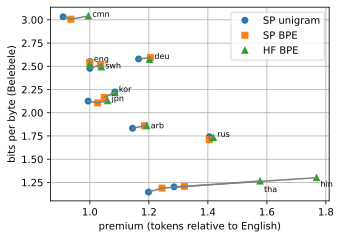

In [17]:
def lang_bpb(name, seed, split, lang):
    nll = np.sum(run_of(name, seed)['nll'][split][lang])
    return nll / (np.sum(TOKLM['n_bytes'][split][lang]) * LN2)

TOKS = list(LM_TOKS)
tab = {}
for name in TOKS:
    n = {l: sum(TOKLM['tokenizers'][name]['n_tokens']['belebele'][l])
         for l in LANGS}
    for l in LANGS:
        b = [lang_bpb(name, s, 'belebele', l) for s in SEEDS]
        h = [lang_bpb(name, s, 'heldout', l) for s in SEEDS]
        tab[name, l] = dict(premium=n[l] / n['eng_Latn'],
                            bpb_belebele=np.mean(b), seed_range=np.ptp(b),
                            bpb_heldout=np.mean(h), heldout_range=np.ptp(h))
TAB = pd.DataFrame(tab).T.rename_axis(['tokenizer', 'lang'])
say(f'Belebele and held-out bits per byte {TIER_LM}')
WIDE = TAB.unstack(0).loc[list(LANGS)].round(3)
for part in (['premium', 'bpb_belebele', 'seed_range'],
             ['bpb_heldout', 'heldout_range']):
    say(WIDE[part].to_string())

def passage_bpb(name):
    """Per-passage bits per byte, averaged over languages and seeds."""
    B = np.array([TOKLM['n_bytes']['belebele'][l] for l in LANGS], float)
    return np.mean([np.array([run_of(name, s)['nll']['belebele'][l]
                              for l in LANGS]) / (B * LN2) for s in SEEDS],
                   axis=(0, 1))

macro = {name: passage_bpb(name) for name in TOKS}
for a, b in itertools.combinations(TOKS, 2):
    r = d2l.paired_bootstrap(macro[a], macro[b])
    say(f'macro bits per byte, {a} - {b}: {r.mean:+.4f} '
        f'[{r.ci[0]:+.4f}, {r.ci[1]:+.4f}] over {r.n} passages')
bpb = TAB.bpb_belebele.unstack(0).loc[list(LANGS)]
prem = TAB.premium.unstack(0).loc[list(LANGS)]
rng_ = TAB.seed_range.unstack(0).loc[list(LANGS)]
for l in LANGS:  # C4, per language: unigram against BPE at equal V
    d = bpb.loc[l, 'SP unigram'] - bpb.loc[l, 'SP BPE']
    noise = rng_.loc[l, ['SP unigram', 'SP BPE']].max()
    say(f'{l}: unigram - BPE {d:+.3f} bits per byte (seed range '
        f'{noise:.3f}): ' + ('not distinguished' if abs(d) <= noise
                             else 'differs'))
effect = (bpb['SP unigram'] - bpb['SP BPE']).abs() / bpb['SP BPE']
spread = prem.max() / prem.min()  # per tokenizer, across languages
say(f'unigram against BPE moves a language by at most {effect.max():.1%} '
    f'of its bits per byte ({effect.idxmax()}); under one tokenizer the '
    f'premium spans a factor of {spread.min():.2f}-{spread.max():.2f} '
    'across languages')

d2l.plot([prem[t].to_numpy() for t in TOKS] +
         [prem.loc[l].to_numpy() for l in LANGS],
         [bpb[t].to_numpy() for t in TOKS] +
         [bpb.loc[l].to_numpy() for l in LANGS],
         xlabel='premium (tokens relative to English)',
         ylabel='bits per byte (Belebele)', legend=TOKS,
         fmts=('o', 's', '^') + ('C7-',) * len(LANGS), figsize=(5, 3.5))
for l in LANGS:
    d2l.plt.gca().annotate(l[:3], (prem.loc[l].max(), bpb.loc[l].iloc[-1]),
                           xytext=(4, 0), textcoords='offset points',
                           fontsize=8)

<!-- d2l:prose id=tokenizers-md-16 fw=all -->

At T1 scale the algorithm matters little. Unigram against BPE at the same
vocabulary size changes a language's bits per byte by at most 3.6%
(Thai), and their averages over languages differ by 0.002 bits per byte,
with an interval that barely excludes zero. Both SentencePiece models are
better than the byte-level BPE by about 0.02 bits per byte. In the plot
the lines are short. The premium, by contrast, varies a lot between
languages under every tokenizer: the most expensive language needs 1.5 to
1.8 times the tokens of the cheapest. Seven of the ten languages show a
unigram-BPE difference larger than their seed range, but these
differences are small, they go both ways, and two seeds cannot rank
tokenizers language by language. Bostrom and Durrett (2020) found the
unigram model better than BPE for pretraining BERT-sized models in English
and Japanese; our small models can neither confirm nor refute that at
their scale.

One large tokenizer effect stands out: the byte-level BPE gives Hindi a
premium of 1.77, against 1.32 for SentencePiece's BPE, and also the worst
Hindi bits per byte of the three (1.30 against 1.21, beyond the seed
range). This is the split rule again. SentencePiece does not cut inside a
word of one script, while the byte-level BPE inherits the cuts at every
vowel sign. So a tokenizer decides how many tokens a language costs far
more than how well a model predicts it, at least at this scale, and its
pre-tokenization rule can matter more than its algorithm. The vertical
order of the languages, finally, says little: Chinese sits near 3 bits
per byte and Hindi near 1.2 because their scripts spend their bytes
differently, not because one is harder to model.

## Vocabulary Size and Pre-Tokenization

Every tokenizer so far had a vocabulary size chosen by habit: 16,384 here,
50,257 for GPT-2, 151,669 for Qwen3. Is there a better reason for a
number? The vocabulary enters a model twice. It sets the size of the
embedding matrix, $V$ rows of width $d$, which with tied embeddings is
also the output layer that computes a logit for every piece at every
position. And through the tokenizer it sets how many tokens a text
becomes. A larger $V$ makes every token more expensive and the text
shorter. That trade-off can be written down.

Training a transformer with $N$ parameters costs about $6N$ floating-point
operations per token, two for each parameter in the forward pass and four
in the backward pass. Let $A$ be the parameters outside the vocabulary
matrix. With tied embeddings the vocabulary adds $Vd$ parameters, used
once per position by the output layer (the input lookup costs nothing).
A token covers $\bar b(V)$ bytes on average, so the compute per byte of
text is

$$
C(V) = \frac{6\,(A + Vd)}{\bar b(V)}.
$$

To find the best $V$, take logarithms and differentiate with respect to
$\log V$:

$$
\frac{d \log C}{d \log V} = \frac{Vd}{A + Vd}
- \frac{d \log \bar b}{d \log V}.
$$

The first term is the *softmax share* $s(V)$, the fraction of parameters
in the vocabulary matrix. The second is the *elasticity of compression*
$\varepsilon(V)$: by how many percent the bytes per token grow when the
vocabulary grows by one percent. The derivative is zero where the two are
equal, and if $\varepsilon$ is roughly constant near that point we can
solve for $V$:

$$
\varepsilon(V^*) = s(V^*) = \frac{V^* d}{A + V^* d},
\qquad
V^* = \frac{\varepsilon}{1 - \varepsilon} \cdot \frac{A}{d}.
$$

In words, growing the vocabulary is worth it as long as the fraction of
tokens it saves exceeds the fraction of compute it adds. Since
compression gains shrink as the vocabulary grows, $\varepsilon$ falls with
$V$ while $s$ rises, and the crossing is a minimum. For a model with 24
blocks of width $d = 1{,}024$, so $A = 12 \cdot 24 \cdot 1024^2 \approx
302$ million, and $\varepsilon = 0.1$, the formula gives $V^* = 32{,}768$.
Two consequences are visible without numbers: a larger model (larger $A$)
deserves a larger vocabulary, and so does text that keeps compressing as
pieces are added (larger $\varepsilon$), such as many languages at once.

Tao and colleagues (2024) reach the same direction with a model that
also lets the vocabulary change the loss, which ours holds fixed. They
estimate, for instance, that Llama 2 70B would have been better served by
at least 216,000 pieces than by its 32,000. Our model is the compute half
of their argument, and it is enough to see where released vocabularies
sit.

To measure $\bar b(V)$ we use a property of BPE: merges are learned in
order, so the first $V$ ids of a trained vocabulary, with the merges that
made them, are exactly the tokenizer that training would have produced had
it stopped at $V$. One BPE of 65,536 pieces therefore gives $\bar b$ at
every smaller size. We train one on English FineWeb-Edu documents and one
on the ten-language slice, measure bytes per token on held-out text at
seven sizes, and fit a smooth increasing curve to $\log \bar b$ against
$\log V$; its slope is the elasticity. A synthetic curve with
$\bar b = cV^{0.1}$ checks the code against the formula.

In [18]:
R2 = d2l.r2_tokenizer()
R2_RAW = d2l.r2_tokenizer(raw=True)
SHARDS = d2l.fwedu_shards('100m')

def shard_texts(shards, n_bytes, start=0):
    """Decoded documents of a shard set, in order, until n_bytes bytes."""
    out, b = [], 0
    for _, ids in shards.iter_docs(start):
        if b >= n_bytes:
            break
        out.append(R2_RAW.decode(ids[:-1].tolist()))
        b += len(out[-1].encode())
    return out

tic = time.time()
ENG = shard_texts(SHARDS, sum(len(t.encode()) for t in LM_TEXT))
BIG = {'English': d2l.train_hf_bpe(ENG, 65_536, ['<|endoftext|>']),
       'ten languages': d2l.train_hf_bpe(LM_TEXT, 65_536,
                                         ['<|endoftext|>'])}
say(f'two BPEs of 65,536 pieces, on {len(ENG):,} English documents and '
    f'on the slice ({sum(len(t.encode()) for t in ENG) / 1e6:.0f} and '
    f'{sum(len(t.encode()) for t in LM_TEXT) / 1e6:.0f} MB): '
    f'{time.time() - tic:.0f} s')
GRID = [2**k for k in range(10, 17)]
EVAL = {'English': HELD['eng_Latn'],
        'ten languages': [t for l in LANGS for t in HELD[l]]}

def bytes_per_token(tok, texts):
    return (sum(len(t.encode()) for t in texts)
            / sum(len(e.ids) for e in tok.encode_batch(texts)))

BBAR = pd.DataFrame({k: [bytes_per_token(d2l._bpe_prefix(BIG[k], V),
                                         EVAL[k]) for V in GRID]
                     for k in BIG}, index=GRID)
# log b-bar as a smooth monotone function of log V: its value and its
# slope (the elasticity) come from the same curve
LOG_BBAR = {k: PchipInterpolator(np.log(GRID), np.log(BBAR[k]))
            for k in BIG}
bbar = lambda k, V: np.exp(LOG_BBAR[k](np.log(V)))
elasticity = lambda k, V: LOG_BBAR[k].derivative()(np.log(V))
d, A = 1024, 12 * 24 * 1024**2   # the reference transformer of D3
share = lambda V: V * d / (A + V * d)
cost = lambda V, bb: 6 * (A + V * d) / bb  # FLOP per byte
say(pd.concat([BBAR.round(3).add_prefix('bytes/token, '),
               pd.DataFrame({k: elasticity(k, np.array(GRID, float))
                             for k in BIG}, index=GRID
                            ).round(3).add_prefix('elasticity, '),
               pd.Series({V: share(V) for V in GRID},
                         name='softmax share').round(3)], axis=1))

V = np.geomspace(1_000, 200_000, 20_001)  # D3 check on b-bar = c V^0.1
v_star = 0.1 * A / (d * 0.9)
v_grid = V[np.argmin(cost(V, V**0.1))]
assert abs(v_grid / v_star - 1) < 0.01
say(f'synthetic b-bar = c V^0.1: grid minimum {v_grid:,.0f}, formula '
    f'{v_star:,.0f}')
FINE = np.geomspace(GRID[0], GRID[-1], 2_001)
for k in BIG:  # the measured minimum and the elasticity crossing
    v_min = FINE[np.argmin(cost(FINE, bbar(k, FINE)))]
    gap = elasticity(k, FINE) - share(FINE)
    cross = FINE[np.argmax(gap < 0)] if (gap < 0).any() else None
    say(f'{k}: cost minimum at V = {v_min:,.0f}; elasticity falls to '
        'the softmax share at ' + (f'V = {cross:,.0f}' if cross else
                                   'no V in the grid'))

two BPEs of 65,536 pieces, on 9,566 English documents and on the slice (46 and 46 MB): 40 s


       bytes/token, English  bytes/token, ten languages  elasticity, English  \
1024                  2.431                       2.018                0.236   
2048                  2.847                       2.425                0.219   
4096                  3.296                       2.853                0.189   
8192                  3.710                       3.297                0.154   
16384                 4.090                       3.764                0.112   
32768                 4.361                       4.250                0.069   
65536                 4.529                       4.721                0.036   

       elasticity, ten languages  softmax share  
1024                       0.280          0.003  
2048                       0.249          0.007  
4096                       0.221          0.014  
8192                       0.200          0.027  
16384                      0.183          0.053  
32768                      0.162          0.100  
65536    

<!-- d2l:prose id=tokenizers-md-17 fw=all -->

For English the elasticity falls from 0.24 at 1,024 pieces to 0.04 at
65,536, while the softmax share at $d = 1{,}024$ rises from 0.3% to 18%.
They cross near 27,000 pieces, which is also where the cost curve has its
minimum (the two numbers agree because both come from one fitted curve).
Ten-language text keeps compressing for longer, with an elasticity of 0.16
at 32,768 pieces against English's 0.07, and its optimum moves to about
51,000 pieces. The synthetic check recovers the formula's 32,768. The
right panel of the plot shows how flat the minimum is: a vocabulary half
or twice the optimal size costs only a few percent more compute per byte.
Any round number near the optimum will do; the cost model does not pin
the vocabulary down to better than a factor of two.

Where do released tokenizers sit? For each one we measure bytes per token
on the same English held-out text and compute, from the model's own
configuration and without loading weights, the share of its parameters in
the vocabulary matrix. The reference tokenizer is placed at the width of
the next chapter's reference model, $d = 768$.

English held-out text; tied embeddings
                   V  bytes_per_token       d  non_embedding_M  softmax_share  \
GPT-2        50257.0            4.568   768.0           85.842          0.310   
Qwen3       151936.0            4.454  1024.0          440.467          0.261   
Qwen3.5     248320.0            4.410  1024.0          498.113          0.338   
reference    32768.0            4.374   768.0          113.277          0.182   
o200k_base  200019.0            4.677     NaN              NaN            NaN   

            GFLOP_per_kB  
GPT-2            163.466  
Qwen3            802.862  
Qwen3.5         1023.749  
reference        189.905  
o200k_base           NaN  


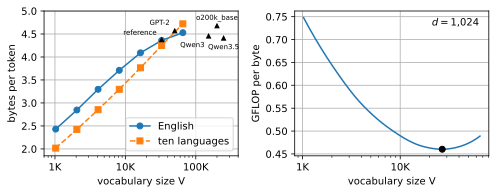

In [19]:
def released_params(model_id):
    """(vocabulary rows, width, parameters) from the pinned configuration,
    on the meta device: no weights are loaded."""
    cfg = transformers.AutoConfig.from_pretrained(
        model_id, revision=d2l.HF_REVISIONS[model_id]).get_text_config()
    with torch.device('meta'), warnings.catch_warnings():
        warnings.simplefilter('ignore')  # kernels a CPU cannot run
        m = transformers.AutoModelForCausalLM.from_config(cfg)
    return cfg.vocab_size, cfg.hidden_size, d2l.num_params(m)

FIT = {'GPT-2': (50_257, 768, 124_439_808),  # OpenAI's released config
       'Qwen3': released_params('Qwen/Qwen3-0.6B-Base'),
       'Qwen3.5': released_params('Qwen/Qwen3.5-0.8B-Base'),
       'reference': (32_768, 768, 138_442_752),  # chap. 21's model
       'o200k_base': (200_019, None, None)}
TOKENIZERS = {**RELEASED, 'reference': R2}
rows = {}
for k, (Vk, dk, n) in FIT.items():
    bb = sum(len(t.encode()) for t in HELD['eng_Latn']) / sum(map(
        len, d2l._doc_token_ids(TOKENIZERS[k], HELD['eng_Latn'])))
    row = dict(V=Vk, bytes_per_token=bb)
    if dk:
        Ak = n - Vk * dk  # tied embeddings: one V x d matrix
        row.update(d=dk, non_embedding_M=Ak / 1e6,
                   softmax_share=Vk * dk / (Ak + Vk * dk),
                   GFLOP_per_kB=6 * (Ak + Vk * dk) / bb * 1e3 / 1e9)
    rows[k] = row
say('English held-out text; tied embeddings')
say(pd.DataFrame(rows).T.round(3))

fig, axes = d2l.plt.subplots(1, 2, figsize=(7, 2.8))
d2l.plot(GRID, [BBAR[k].to_numpy() for k in BIG], 'vocabulary size V',
         'bytes per token', legend=list(BIG), xscale='log', axes=axes[0],
         fmts=('-o', '--s'))
LABEL_AT = {'reference': ((-5, 5), 'right'), 'GPT-2': ((-5, 6), 'right'),
            'Qwen3': ((-4, -11), 'right'), 'Qwen3.5': ((0, -11), 'center'),
            'o200k_base': ((0, 6), 'center')}  # text clear of the curves
for k in TOKENIZERS:
    axes[0].plot(rows[k]['V'], rows[k]['bytes_per_token'], 'k^',
                 markersize=4)
    axes[0].annotate(k, (rows[k]['V'], rows[k]['bytes_per_token']),
                     xytext=LABEL_AT[k][0], textcoords='offset points',
                     ha=LABEL_AT[k][1], fontsize=7)
axes[0].set_xlim(700, 4e5)  # every released vocabulary on the panel
axes[0].set_ylim(1.85, 5.0)
axes[0].legend(list(BIG), loc='lower right')
c = cost(FINE, bbar('English', FINE)) / 1e9
d2l.plot(FINE, c, 'vocabulary size V', 'GFLOP per byte', xscale='log',
         axes=axes[1])
axes[1].plot(FINE[np.argmin(c)], c.min(), 'ko')
axes[1].text(0.95, 0.9, '$d = 1{,}024$', transform=axes[1].transAxes,
             ha='right')
for ax, n in zip(axes, (3, 2)):
    ax.set_xticks([1e3, 1e4, 1e5][:n], ['1K', '10K', '100K'][:n])
fig.tight_layout()

<!-- d2l:prose id=tokenizers-md-18 fw=all -->

On English all five tokenizers cover between 4.4 and 4.7 bytes per token,
although their vocabularies range from 32,768 to 248,320 pieces. Beyond a
few tens of thousands of pieces, English is compressed nearly as far as it
goes. The small released models spend a quarter to a third of their
parameters on the vocabulary matrix (GPT-2 small 31%, Qwen3-0.6B 26%,
Qwen3.5-0.8B 34%), and the reference model 18%. By the cost model these
small models have more vocabulary than English needs. Their vocabularies
were not chosen for them alone, however: one tokenizer serves a whole
family of model sizes up to hundreds of billions of parameters, and many
languages, and the equation says that both push $V$ up. The
reference tokenizer, measured on the training shard later in this section,
needs only 1% more tokens than GPT-2's on English prose with a matrix 35%
smaller.

A few practical rules come from costs the model leaves out. Round $V$ up
to a multiple of 64 or 128 so that the output layer's matrix multiply fits
the GPU's tiles; Qwen3's tokenizer has 151,669 ids and its matrix 151,936
rows. Reserve ids for special tokens that a later stage will need, so that
adding a chat or tool token does not mean resizing the model. And tie the
input and output embeddings in small models, which halves the vocabulary's
parameters.

### Numbers, Whitespace and Code

Before any merge is learned, the pre-tokenization rule has already decided
much of how a tokenizer treats numbers and code.
that section showed GPT-2 cutting 12345678
wherever BPE had found frequent fragments and `o200k_base` cutting runs of
digits into groups of at most three. Qwen3, Qwen3.5 and the reference
tokenizer go further and make every digit its own token. For code, what
matters is whitespace. An indented line starts with a run of spaces, and a
tokenizer with no piece for long runs spends a token on every space or two.
We measure both, on a passage full of numbers and on the first 2,000 lines
of the book's own library, `d2l/torch.py`.

In [20]:
VB = {k: d2l._vocab_bytes(t) for k, t in TOKENIZERS.items()}

def pieces(k, s):
    return '|'.join(VB[k][i].decode('utf-8', 'replace')
                    for i in d2l._doc_token_ids(TOKENIZERS[k], [s])[0])

say(pd.DataFrame({s: {k: pieces(k, s) for k in TOKENIZERS}
                  for s in ('12345678', '3.14159', '1,234,567')}))
NUMBERS = ('In 2019 the plant produced 1,234,567 tonnes, up 12.5% from '
           '1,097,393 in 2018; the price rose from $3,456.78 to $3,901.25 '
           'per unit, and 47 of its 365 days ran at 98.6% capacity.\n'
           '| year | output | share |\n| 2016 | 864,512 | 31.4% |\n'
           '| 2017 | 970,031 | 33.9% |\n| 2018 | 1,097,393 | 36.2% |\n')
with open(d2l.__file__, encoding='utf-8') as f:
    CODE = ''.join(itertools.islice(f, 2000))
rows = {}
for k, tok in TOKENIZERS.items():
    ids = d2l._doc_token_ids(tok, [NUMBERS])[0]
    digit_tokens = [i for i in ids if any(48 <= c <= 57 for c in VB[k][i])]
    code = d2l._doc_token_ids(tok, [CODE])[0]
    spaces = [len(b) for b in VB[k] if b and b.strip(b' ') == b'']
    rows[k] = dict(digits_per_token=sum(c.isdigit() for c in NUMBERS)
                   / len(digit_tokens),
                   code_tokens_per_line=len(code) / CODE.count('\n'),
                   code_bytes_per_token=len(CODE.encode()) / len(code),
                   longest_space_token=max(spaces, default=0))
say(pd.DataFrame(rows).T.round(2))

                   12345678        3.14159          1,234,567
GPT-2            123|45|678     3|.|14|159     1|,|234|,|5|67
o200k_base       123|456|78     3|.|141|59      1|,|234|,|567
Qwen3       1|2|3|4|5|6|7|8  3|.|1|4|1|5|9  1|,|2|3|4|,|5|6|7
Qwen3.5     1|2|3|4|5|6|7|8  3|.|1|4|1|5|9  1|,|2|3|4|,|5|6|7
reference   1|2|3|4|5|6|7|8  3|.|1|4|1|5|9  1|,|2|3|4|,|5|6|7


            digits_per_token  code_tokens_per_line  code_bytes_per_token  \
GPT-2                   2.12                 19.25                  2.12   
o200k_base              2.07                 10.63                  3.83   
Qwen3                   1.00                 10.67                  3.82   
Qwen3.5                 1.00                 11.36                  3.59   
reference               1.00                 17.64                  2.31   

            longest_space_token  
GPT-2                       1.0  
o200k_base                128.0  
Qwen3                     128.0  
Qwen3.5                   128.0  
reference                   2.0  


<!-- d2l:prose id=tokenizers-md-19 fw=all -->

The three rules cut 12345678 in three ways. Single digits are the only rule
under which every number is cut the same way, digit by digit, so that the
model sees place value in the same form everywhere. They cost about twice
as many tokens on the numeric passage as GPT-2's or `o200k_base`'s
groups. On code, `o200k_base` and the Qwen tokenizers have pieces for
whitespace runs of up to 128 bytes and need about 11 tokens per line of
the library. GPT-2's has none and needs 19. The reference tokenizer, whose
longest whitespace piece is two spaces, needs 17.6, about 65% more than
Qwen3's. It was trained on educational web prose, where long runs of
spaces are rare. A model trained on it will read code expensively, and
only a change of vocabulary can fix that, which is the subject of the next
part of this section.

## Extending a Trained Vocabulary

Suppose a trained model's tokenizer fragments a language you care about.
Qwen3-0.6B-Base is an example: its tokenizer needs 4.5 times English's
tokens for Hindi, while that of its successor Qwen3.5 needs 2.0. Part of
Qwen3.5's improvement is a larger vocabulary, and part is a split rule that
keeps combining marks with their letters. Training a new model with a
better tokenizer is out of reach for most of us. Can we add pieces to the
old one instead?

Adding pieces to a tokenizer is easy. The hard question is what to put in
their rows of the embedding matrix, which in Qwen3-0.6B are shared between
input and output. that section showed that training
places the row of a token near the rows of tokens used in similar
contexts. An initialization decides where in that space a new row starts.
We compare three simple choices. *Random* rows are drawn from the model's
own initializer. *Mean* rows are the mean of all old rows plus noise of 1%
of their standard deviation, so that no two rows are equal. The
*decomposition* uses the old tokenizer: it splits each new piece into old
pieces, and the new row is the mean of their rows. WECHSEL
(Minixhofer and colleagues, 2022) and FOCUS (Dobler and de Melo, 2023)
place a new row more carefully, as a weighted average of the rows of old
pieces that are similar to it according to auxiliary word embeddings; we
describe them and do not implement them. `extend_vocab` implements the
three choices for a Transformers model and tokenizer. It resizes the input
matrix and, if the embeddings are untied, the output matrix too, and it
updates `config.vocab_size`. Forgetting either of the last two is a common
bug that produces no error until the first new id is used.

In [21]:

def extend_vocab(model, tokenizer, new_pieces, init='random', seed=0):
    """Add new_pieces to a Transformers tokenizer (as added tokens, which
    are matched before the model's own segmentation) and rows for them to
    the model's input and, if untied, output matrices, initialized by
    init: 'random' (normal, the config's initializer_range), 'mean' (the
    mean of the old rows plus noise of 1% of their standard deviation, so
    that no two rows are equal) or 'decomp' (the mean of the old rows of
    the pieces the old tokenizer splits the new piece into). Returns
    (model, tokenizer) with config.vocab_size updated."""
    if init not in ('random', 'mean', 'decomp'):
        raise ValueError(f'unknown init {init!r}')
    pieces, n_old = list(new_pieces), len(tokenizer)
    parts = tokenizer(pieces, add_special_tokens=False)['input_ids']
    if tokenizer.add_tokens(pieces) != len(pieces):
        raise ValueError('a new piece is in the vocabulary already')
    out = model.get_output_embeddings()
    tied = out is None or out.weight is model.get_input_embeddings().weight
    old = [model.get_input_embeddings().weight] + ([] if tied
                                                   else [out.weight])
    old = [W.detach()[:n_old].float().cpu() for W in old]
    model.resize_token_embeddings(len(tokenizer), mean_resizing=False)
    mats = [model.get_input_embeddings().weight] + (
        [] if tied else [model.get_output_embeddings().weight])
    g = torch.Generator().manual_seed(seed)
    std = model.config.get_text_config().initializer_range
    k, d = len(pieces), old[0].shape[1]
    with torch.no_grad():
        for W, W0 in zip(mats, old):
            if init == 'random':
                new = torch.randn(k, d, generator=g) * std
            elif init == 'mean':
                new = W0.mean(0) + 0.01 * W0.std() * torch.randn(
                    k, d, generator=g)
            else:
                new = torch.stack([W0[ids].mean(0) for ids in parts])
            W[n_old:n_old + k] = new.to(W.device, W.dtype)
    model.config.get_text_config().vocab_size = len(tokenizer)
    return model, tokenizer

<!-- d2l:prose id=tokenizers-md-20 fw=all -->

The new pieces come from a byte-level BPE of 8,192 pieces trained on
30,000 Hindi documents. Its split rule keeps letters and their combining
marks together and never puts a space inside a piece. This matters for
English. The new pieces are added as *added tokens*, which the tokenizer
matches before its own segmentation, so a new piece that contained an
ASCII character would change how some English text is cut. We keep the
pieces that hold at least two Devanagari characters and no ASCII byte and
that are not already in Qwen3's vocabulary, and add the first 4,096 of
them in merge order. The cell then checks that 1,000 lines of English get
the same ids as before.

In [22]:
HI_REGEX = r"""[\p{L}\p{M}]+|\p{N}|[^\s\p{L}\p{M}\p{N}]+|\s+"""
HI_TRAIN = HINDI[HINDI.part == 'ext_train'].text.tolist()
HI_HELD = HINDI[HINDI.part == 'ext_heldout'].text.tolist()
tic = time.time()
hi_bpe = d2l.train_hf_bpe(HI_TRAIN, 8192, ['<|endoftext|>'], regex=HI_REGEX)
QWEN = RELEASED['Qwen3']
in_qwen, cand, NEW = QWEN.get_vocab(), 0, []
for i, b in enumerate(d2l._vocab_bytes(hi_bpe)):  # ids in merge order
    try:
        s = b.decode('utf-8')
    except (AttributeError, UnicodeDecodeError):  # special, partial
        continue
    if (len(b) > 1 and not any(c < 128 for c in b)
            and len(regex.findall(r'\p{Devanagari}', s)) >= 2):
        cand += 1
        if hi_bpe.id_to_token(i) not in in_qwen:
            NEW.append(s)
say(f'Hindi BPE in {time.time() - tic:.0f} s: {cand:,} Devanagari '
    f'pieces, {len(NEW):,} new to Qwen3; the first {N_NEW:,} are added')
assert len(NEW) >= N_NEW
NEW = NEW[:N_NEW]
EXT_TOK = copy.deepcopy(QWEN)
EXT_TOK.add_tokens(NEW)
ascii_lines = [l for l in lines(HELD['eng_Latn']) if l.isascii()][:1000]
assert len(ascii_lines) == 1000
assert (QWEN(ascii_lines, add_special_tokens=False)['input_ids']
        == EXT_TOK(ascii_lines, add_special_tokens=False)['input_ids'])
say(f'1,000 ASCII lines: the same ids before and after extension')
hb = sum(len(t.encode()) for t in HI_HELD)
for name, tok in (('Qwen3', QWEN), ('Qwen3 + Hindi', EXT_TOK),
                  ('Qwen3.5', RELEASED['Qwen3.5'])):
    n = sum(map(len, d2l._doc_token_ids(tok, HI_HELD)))
    say(f'{name}: {hb / n:.2f} bytes per token on 500 held-out Hindi '
        'documents')
say('new pieces:', ' '.join(NEW[:12]), '...', ' '.join(NEW[-6:]))

Hindi BPE in 10 s: 7,154 Devanagari pieces, 7,153 new to Qwen3; the first 4,096 are added


1,000 ASCII lines: the same ids before and after extension


Qwen3: 2.79 bytes per token on 500 held-out Hindi documents
Qwen3 + Hindi: 5.28 bytes per token on 500 held-out Hindi documents


Qwen3.5: 6.13 bytes per token on 500 held-out Hindi documents
new pieces: के है ें ने ार या में की से कर को कि ... शुरुआती विधायकों ्न बंग बेचने हिमाचल


<!-- d2l:prose id=tokenizers-md-21 fw=all -->

Of the Hindi BPE's 7,154 pieces with at least two Devanagari characters,
7,153 are new to Qwen3. The first ones are endings and particles such as
के, है and में; the last ones are whole words such as हिमाचल (Himachal).
English is cut exactly as before. The extended tokenizer reads 5.28 bytes
of Hindi per token against 2.79 before, close to Qwen3.5's 6.13, so Hindi
needs about half the tokens it did. That is the whole benefit the
tokenizer can deliver, and it is not yet a benefit to the model. Whether
the model can use the new tokens depends on their rows.

### Initialization at Step Zero

Before any training, three measurements show what an initialization did.
The first is the probability the new tokens receive on English text, where
none of them should appear. If it is large, the new rows have hijacked the
softmax, and the model has become worse at English before training starts.
The second is the probability they receive on Hindi text, where about half
of the next tokens are new ones. The third is bits per byte on held-out
Hindi documents, on Belebele's Hindi passages and on English documents.
Bits per byte is the right measure here because the extended and the
original tokenizers cut Hindi differently. English ids are unchanged, so
only the softmax's normalizer, which now sums over the new rows as well,
can move English. The cell also checks an identity of the decomposition.
With tied embeddings, the output row of a new token is the mean of its
pieces' rows, so its logit is the mean of their logits.

In [23]:
@torch.no_grad()
def new_mass(model, tok, texts, lo):
    """Mean probability of the ids lo and above (the new tokens) over the
    positions of the first 256 tokens of each text."""
    out = []
    for ids in d2l._doc_token_ids(tok, texts):
        x = torch.tensor([ids[:256]], device=model.device)
        p = model(input_ids=x).logits[0].float().softmax(-1)
        out.append(p[:, lo:].sum(-1).mean().item())
    return np.array(out)

def bpb(model, tok, texts):
    return d2l.bits_per_byte(model, tok, texts, ctx_len=N_EXT['ctx_len'])

def step0(model, tok):
    """The step-0 diagnostics of one model and tokenizer: new-token mass on
    English and on Hindi contexts, Hindi, Belebele and English bits per
    byte, Hindi bytes per token, and per-passage Belebele bits per byte."""
    per = np.array([bpb(model, tok, [p]) for p in PASSAGES])
    w = np.array([len(p.encode()) for p in PASSAGES])
    k = N_EXT['contexts']
    en, hi = ((new_mass(model, tok, EN_DOCS[:k], LO),
               new_mass(model, tok, HI_DOCS[:k], LO)) if len(tok) > LO
              else (np.zeros(1), np.zeros(1)))
    n = sum(map(len, d2l._doc_token_ids(tok, HI_DOCS)))
    return dict(new_mass=float(en.mean()), new_mass_max=float(en.max()),
                hindi_new_mass=float(hi.mean()),
                hindi_bpb=bpb(model, tok, HI_DOCS),
                belebele_bpb=float((per * w).sum() / w.sum()),
                english_bpb=bpb(model, tok, EN_DOCS),
                hindi_bytes_per_token=sum(len(t.encode())
                                          for t in HI_DOCS) / n,
                per_passage=per.round(5).tolist())

@torch.no_grad()
def decomp_check(model, tok, n=64):
    """Largest |logit(new) - mean(logit(its pieces))| over the first n
    new tokens and the positions of two English contexts, and the
    rounding bound of the stored rows' dtype."""
    W = model.get_output_embeddings().weight
    parts = QWEN(NEW[:n], add_special_tokens=False)['input_ids']
    worst = 0.0
    for ids in d2l._doc_token_ids(tok, EN_DOCS[:2]):
        x = torch.tensor([ids[:128]], device=W.device)
        h = model.get_decoder()(input_ids=x).last_hidden_state[0].float()
        new = h @ W[LO:LO + n].float().T
        mean = torch.stack([(h @ W[p].float().T).mean(1) for p in parts], 1)
        tol = (1e-5 if W.dtype == torch.float32 else 2**-8) * (
            h.abs() @ W[LO:LO + n].float().abs().T) + 1e-5
        assert ((new - mean).abs() <= tol).all()
        worst = max(worst, (new - mean).abs().max().item())
    return worst

<!-- d2l:prose id=tokenizers-md-22 fw=all -->

The four arms are the unextended model with its own tokenizer, the
*control*, and the three initializations (seed 0). All four read the same
500 Hindi documents, 488 Belebele passages and 200 English validation
documents, in bf16.

In [24]:
BASE, _ = d2l.load_hf(EXT_MODEL, dtype=torch.float32 if SMALL
                      else torch.bfloat16)
VAL = d2l.fwedu_shards('val')
with gzip.open(os.path.join(VAL.root, 'val.jsonl.gz'), 'rt',
               encoding='utf-8') as f:
    VAL_TEXT = [json.loads(line) for line in f]
EN_DOCS = [r['text'] for r in VAL_TEXT[:N_EXT['english']]]
HI_DOCS, PASSAGES = HI_HELD[:N_EXT['hindi']], BELE['hin_Deva'][
    :N_EXT['passages']]
LO = len(QWEN)  # the first new id

tic = time.time()
STEP0 = {'control': step0(BASE, QWEN)}
for init in ('random', 'mean', 'decomp'):
    model, tok = d2l.extend_vocab(copy.deepcopy(BASE), copy.deepcopy(QWEN),
                                  NEW, init=init, seed=0)
    assert model.config.get_text_config().vocab_size == len(tok) == LO + N_NEW
    STEP0[init] = step0(model, tok)
    if init == 'decomp':
        say(f'decomposition identity: largest logit difference '
            f'{decomp_check(model, tok):.2e} ({model.dtype})')
    del model
    d2l.lm_free()
say(f'step 0 on {len(HI_DOCS)} Hindi documents, {len(PASSAGES)} Belebele '
    f'passages, {len(EN_DOCS)} English documents'
    + (' (the small CPU path)' if SMALL else ''),
    f'{time.time() - tic:.0f} s', d2l.lm_peak())
say(pd.DataFrame({k: {c: v for c, v in s.items() if c != 'per_passage'}
                  for k, s in STEP0.items()}).T.round(4))
per = {k: np.array(s['per_passage']) for k, s in STEP0.items()}
for init in ('mean', 'decomp'):  # C5 at step 0, over passages
    r = d2l.paired_bootstrap(per[init], per['random'])
    say(f'{init} - random, Belebele Hindi bits per byte: {r.mean:+.3f} '
        f'[{r.ci[0]:+.3f}, {r.ci[1]:+.3f}];',
        'lower than random' if r.ci[1] < 0 else 'not lower than random',
        '| new-token mass', 'below' if STEP0[init]['new_mass']
        < STEP0['random']['new_mass'] else 'NOT below', "random's")

Qwen/Qwen3-0.6B-Base@da87bfb608c1: Qwen3ForCausalLM, stop tokens [151643]
0 missing keys; unexpected keys: none
kernels: attention sdpa


decomposition identity: largest logit difference 3.79e-02 (torch.bfloat16)


step 0 on 500 Hindi documents, 488 Belebele passages, 200 English documents 232 s peak 4.0 GiB (11.2
    GiB reserved)
         new_mass  new_mass_max  hindi_new_mass  hindi_bpb  belebele_bpb  \
control       0.0        0.0000          0.0000     0.6163        0.6652   
random        0.0        0.0001          0.0016     2.3854        2.5350   
mean          0.0        0.0000          0.0001     2.8918        3.0657   
decomp        0.0        0.0007          0.7264     1.4797        1.6269   

         english_bpb  hindi_bytes_per_token  
control       0.8225                 2.7872  
random        0.8225                 5.2772  
mean          0.8225                 5.2772  
decomp        0.8225                 5.2772  


mean - random, Belebele Hindi bits per byte: +0.524 [+0.515, +0.533]; not lower than random |
    new-token mass below random's


decomp - random, Belebele Hindi bits per byte: -0.915 [-0.923, -0.906]; lower than random |
    new-token mass below random's


<!-- d2l:prose id=tokenizers-md-23 fw=all -->

No initialization disturbs English. English bits per byte is 0.8225 in all
four arms, and averaged over any English document the new tokens receive
at most 0.07% of the probability. On Hindi the arms differ sharply. The
decomposition gives the new tokens 73% of the probability on Hindi text
and reaches 1.48 bits per byte. Random rows receive 0.2% and reach 2.39.
Mean rows receive almost nothing and reach 2.89, worse than random by
0.52 bits per byte on the Belebele passages (a 95% interval over
passages of 0.52 to 0.53). The control, reading Hindi through Qwen3's
fragmenting tokenizer, is at 0.62.

Why is the mean worse than random? Every mean row is the same vector up
to 1% noise, so every new token receives the same logit at every
position, the average of the old logits. The new tokens can win no
probability, and as inputs they cannot be told apart. The mean
initialization is recommended for a different purpose (Hewitt, 2021, and
the default of Transformers' `resize_token_embeddings`): it keeps new rows
from hijacking the softmax, and that it does here. It does nothing for the
new tokens themselves. The decomposition starts better because a new
token's logit is the mean of its pieces' logits (the identity holds to
bf16 rounding), which is high exactly where the pieces are likely, that
is, on Hindi. Still, 1.48 bits per byte is far from the control's 0.62.
The model has never read the new tokens as inputs, and their rows are only
a guess.

### Continued Training

Training on Hindi decides whether the new rows can be learned. Each
extended arm and the control train for 150 steps of 8 sequences of 1,024
tokens, in two phases, the usual recipe for vocabulary extension. For the
first 50 steps only the new rows train, at a high learning rate of
$3 \times 10^{-3}$, while the rest of the model, including the old rows of
the shared matrix, is frozen; the control has no new rows, so it waits.
Then every parameter trains for 100 steps at a low rate of $10^{-5}$. Each
phase warms up over 10 steps and decays along a cosine, with AdamW.

The low body rate follows from what a released base model is. It ends
pretraining with its learning rate decayed to nearly zero, and raising the
rate again, on small batches of 8,192 tokens, can move it away from where
it ended. A control that got worse in this way would flatter the extended
arms, so the body rate is the largest at which the control, which has
nothing new to learn, stays where it started on Hindi and on English. The
rate of the first phase is the one at which the new rows reached the
lowest Hindi loss. Both were chosen on Hindi documents that are neither in
the training pool nor in the evaluation set, so no reported number was
tuned on them.

All arms read the same documents. An extended arm needs fewer tokens for
them, so in 150 steps it reads more Hindi text than the control does. The
weights are in fp32 with bf16 arithmetic. Gradient checkpointing and a
loss computed in chunks of 1,024 positions keep the
$8{,}192 \times 155{,}765$ matrix of logits from ever existing at once, and
a run fits in about 14 GB of one GPU.

In [25]:
def hindi_docs_for(tok, n_tokens):
    """The first Hindi training documents whose tokens under tok reach
    n_tokens."""
    k, n = 0, 0
    for ids in d2l._doc_token_ids(tok, HI_TRAIN[:5000]):
        k, n = k + 1, n + len(ids) + 1
        if n >= n_tokens:
            return HI_TRAIN[:k]
    raise ValueError('too few Hindi documents for the training pool')

def chunk_ce(h, W, y):
    """Summed cross-entropy of one chunk of positions; checkpointed, so
    its logits are recomputed in the backward pass, never stored."""
    with torch.autocast(h.device.type, dtype=torch.bfloat16,
                        enabled=h.device.type == 'cuda'):
        z = h @ W.T
    return F.cross_entropy(z.float(), y, reduction='sum')

def phase_lr(step):
    """(first phase?, learning rate) at step: the new rows alone at
    embed_lr for the first embed_steps steps, then every parameter at lr;
    each phase warms up over warmup steps and decays by a cosine."""
    E = EXT_TRAIN
    first = step < E['embed_steps']
    s, n = ((step, E['embed_steps']) if first else
            (step - E['embed_steps'], E['steps'] - E['embed_steps']))
    sched = d2l.ProxyCfg(1, 1, 1, warmup_frac=E['warmup'] / n,
                         final_lr_frac=E['final_lr_frac'])
    return first, (E['embed_lr'] if first else E['lr']) * d2l._lr_at(
        s, n, sched)

def train_ext(arm, seed, docs):
    """Continued training of one arm on docs: the new rows alone (body and
    old rows frozen; the control has none, so it waits), then everything
    at a low rate. Returns the Hindi curve, English before and after, the
    batch losses (None while the control waits) and the cost."""
    E = EXT_TRAIN
    model, tok = d2l.load_hf(EXT_MODEL, dtype=torch.float32)
    n_old = len(tok)
    if arm != 'control':
        model, tok = d2l.extend_vocab(model, tok, NEW, init=arm, seed=seed)
    eos = d2l._lm_boundary_id(tok)
    pool = np.array([i for ids in d2l._doc_token_ids(tok, docs)
                     for i in ids + [eos]], dtype=np.uint32)
    stream = d2l._ProxyStream({'hi': pool}, {'hi': 1.0}, E['steps'] * E[
        'batch'] * E['seq_len'], E['seq_len'], E['batch'], seed)
    model.gradient_checkpointing_enable()
    model.config.use_cache = False
    W = model.get_output_embeddings().weight
    assert W is model.get_input_embeddings().weight, 'tied embeddings'
    for p in model.parameters():  # first phase: the new rows only
        p.requires_grad_(p is W)
    rows = torch.arange(len(W), device=W.device)[:, None] >= n_old
    hook = W.register_hook(lambda g: g * rows)
    opt = torch.optim.AdamW([W], lr=E['embed_lr'], betas=(0.9, 0.95),
                            weight_decay=0.0)
    curve, losses = [], []
    evaluate = lambda texts: bpb(model.eval(), tok, texts)
    english = {0: evaluate(EN_DOCS)}
    curve.append((0, evaluate(HI_HELD[:E['curve_docs']])))
    tic = time.time()
    for step in range(E['steps']):
        if step == E['embed_steps']:  # second phase: every parameter
            hook.remove()
            for p in model.parameters():
                p.requires_grad_(True)
            opt = torch.optim.AdamW(model.parameters(), lr=E['lr'],
                                    betas=(0.9, 0.95), weight_decay=0.0)
        first, lr = phase_lr(step)
        if first and arm == 'control':  # no new rows to train
            losses.append(None)
        else:
            model.train()
            for g in opt.param_groups:
                g['lr'] = lr
            X = torch.from_numpy(stream.batch(step)[0]).to(model.device)
            total = 0.0
            for Xm in X.split(E['micro_batch']):
                with torch.autocast(X.device.type, dtype=torch.bfloat16,
                                    enabled=X.device.type == 'cuda'):
                    H = model.get_decoder()(
                        input_ids=Xm[:, :-1]).last_hidden_state
                h, y = H.flatten(0, 1), Xm[:, 1:].flatten()
                loss = sum(checkpoint(
                    chunk_ce, h[i:i + E['loss_chunk']], W,
                    y[i:i + E['loss_chunk']], use_reentrant=False)
                    for i in range(0, len(y), E['loss_chunk'])) / (
                        X.shape[0] * E['seq_len'])
                loss.backward()
                total += loss.item()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            opt.zero_grad(set_to_none=True)
            losses.append(round(total, 4))
        if step + 1 in E['eval_at']:
            curve.append((step + 1, evaluate(HI_HELD[:E['curve_docs']])))
    english[E['steps']] = evaluate(EN_DOCS)
    out = dict(arm=arm, seed=seed, curve=curve, english=english,
               losses=losses, seconds=time.time() - tic,
               train_tokens=len(pool), peak=d2l.lm_peak())
    del model, opt
    d2l.lm_free()
    return out

<!-- d2l:prose id=tokenizers-md-24 fw=all -->

The eight runs, four arms with two data-order seeds each, are read from
the registered results unless regenerated. Hindi bits per byte is measured
along training on 100 held-out documents in fp32, so its values at step 0
differ slightly from the table above; English is measured on the 200
English documents before and after training.

continued training on Hindi at T1 scale (Qwen3-0.6B-Base, 150 steps of 8 x 1,024 tokens)
      control  random   mean  decomp
step                                
0       0.627   2.382  2.876   1.488
25      0.627   1.402  1.134   1.055
50      0.627   1.246  1.026   0.959
100     0.637   1.057  0.933   0.862
150     0.626   1.034  0.918   0.847
    arm  seed  English bpb, step 0  English bpb, step 150
control     0                0.822                  0.825
control     1                0.822                  0.824
 random     0                0.822                  0.832
 random     1                0.822                  0.832
   mean     0                0.822                  0.829
   mean     1                0.822                  0.830
 decomp     0                0.822                  0.828
 decomp     1                0.822                  0.829


<Axes: xlabel='step', ylabel='Hindi bits per byte'>

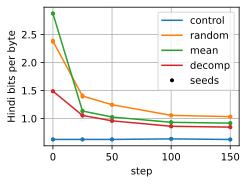

In [26]:
if 'tok-extend' in RERUN:
    docs = hindi_docs_for(QWEN, EXT_TRAIN['pool_tokens'])
    runs = []
    for arm in ('control', 'random', 'mean', 'decomp'):
        for seed in EXT_TRAIN['seeds']:
            runs.append(train_ext(arm, seed, docs))
            r = runs[-1]
            say(f'{arm}, seed {seed}: Hindi bits per byte '
                + ' -> '.join(f'{v:.3f}' for _, v in r['curve'])
                + f', {r["seconds"]:.0f} s, {r["peak"]}')
    TOKEXT = dict(schema='d2l-tok-extend/1', tier=TIER, model=EXT_MODEL,
                  revision=d2l.HF_REVISIONS[EXT_MODEL], config=EXT_TRAIN,
                  n_eval=N_EXT, new_pieces=NEW, n_docs=len(docs),
                  step0=STEP0, runs=runs)
    TOKEXT = json.loads(json.dumps(TOKEXT))
    d2l.lm_save_rerun('tok-extend.json', lambda p: write_json(p, TOKEXT))
elif RESULTS is None:
    raise KeyError(f'{RES_KEY} is not registered: regenerate it with '
                   'D2L_RERUN=1, upload and register it')
else:
    TOKEXT = RESULTS['tok-extend']
assert TOKEXT['new_pieces'] == NEW, 'the new pieces differ from the runs'
assert {k: TOKEXT[k] for k in ('tier', 'model', 'revision', 'config')} == (
    json.loads(json.dumps(dict(tier=TIER, model=EXT_MODEL, config=EXT_TRAIN,
                               revision=d2l.HF_REVISIONS[EXT_MODEL])))), (
    'the registered runs used another model or configuration')
ARMS = ('control', 'random', 'mean', 'decomp')
steps = [s for s, _ in TOKEXT['runs'][0]['curve']]
curves = {a: np.array([[v for _, v in r['curve']] for r in TOKEXT['runs']
                       if r['arm'] == a]) for a in ARMS}
say(f'continued training on Hindi {TIER_EXT}')
say(pd.DataFrame({a: dict(zip(steps, c.mean(0))) for a, c in
                  curves.items()}).round(3).rename_axis('step'))
say(pd.DataFrame([dict(arm=r['arm'], seed=r['seed'], **{
    f'English bpb, step {s}': v for s, v in r['english'].items()})
    for r in TOKEXT['runs']]).round(3).to_string(index=False))
d2l.plot_intervals(steps, {a: (c.mean(0), c.min(0), c.max(0))
                           for a, c in curves.items()}, 'step',
                   'Hindi bits per byte', kind='band',
                   marks={'seeds': ('.', {a: (np.tile(steps, len(c)),
                                              c.ravel())
                                          for a, c in curves.items()})})

<!-- d2l:prose id=tokenizers-md-25 fw=all -->

The control stays flat, from 0.627 to 0.626 bits per byte, so the recipe
does what it was chosen for. The extended arms improve quickly in the
first phase, and the gaps between initializations shrink from between
0.5 and 1.4 bits per byte at step 0 to at most 0.2 at step 150. The decomposition
stays best throughout and ends at 0.85. The mean overtakes random within
25 steps and ends at 0.92 against 1.03. A plausible reason is that random
rows are small vectors in a region the model never visited, while the
mean rows, once training pulls them apart, start among the old ones.
English barely moves, from 0.822 to at most 0.832.

No extended arm reaches the control, however. After 150 steps, 1.2
million tokens, the best is still about 0.2 bits per byte above it. At
this budget the extension halves the number of tokens Hindi needs and
loses a fifth of a bit per byte in prediction. Published extensions
continue training on far more text, often billions of tokens, and how
long the extended model needs to catch up is something 150 steps cannot
tell. The number of new tokens is not the benefit. The benefit is fewer
tokens per byte, and it reaches the model only after the model has
learned to use them.

### Byte Patches

Every tokenizer in this section makes a compression decision once, before
the model sees any data, and the extension experiment showed how hard that
decision is to revisit. The Byte Latent Transformer (Pagnoni and
colleagues, 2024) moves the decision into the model. A small byte-level
model predicts the next byte, and a new *patch* starts wherever its
prediction becomes uncertain, so predictable stretches become long
patches and surprising ones short. The toy below imitates only the
boundary rule, with a character trigram model trained on Hindi text: a
patch ends where the entropy of the next character jumps. It compares
patch lengths with token lengths, both in UTF-8 bytes because a
byte-level token can be part of a character. It says nothing about how
well a model would learn from such patches.

In [27]:
text = ''.join(HI_TRAIN[:2000])
nxt = collections.defaultdict(collections.Counter)
for a, b, c in zip(text, text[1:], text[2:]):
    nxt[a + b][c] += 1
def entropy(ctx):
    n = np.array(list(nxt[ctx].values()), float)
    return float(-(n / n.sum() * np.log2(n / n.sum())).sum()) if len(n) else 8.
para = next(p for t in HI_HELD for p in t.split('\n') if len(p) > 300)
H = np.array([entropy(para[i - 2:i]) for i in range(2, len(para))])
cuts = [0] + [i + 2 for i in range(1, len(H)) if H[i] > H[i - 1] + 0.5]
patches = [len(para[a:b].encode()) for a, b in zip(cuts, cuts[1:]
                                                   + [len(para)])]
toks = {k: [len(VB[k][i]) for i in
            d2l._doc_token_ids(TOKENIZERS[k], [para])[0]]
        for k in ('Qwen3', 'Qwen3.5', 'reference')}
say(f'UTF-8 bytes per patch and per token, one Hindi paragraph of '
    f'{len(para.encode()):,} bytes')
say(pd.DataFrame({'entropy patches': pd.Series(patches).describe(),
                  **{f'{k} tokens': pd.Series(v).describe()
                     for k, v in toks.items()}}).round(2))

UTF-8 bytes per patch and per token, one Hindi paragraph of 1,092 bytes
       entropy patches  Qwen3 tokens  Qwen3.5 tokens  reference tokens
count           134.00        371.00          134.00            432.00
mean              8.15          2.94            8.15              2.53
std               4.00          1.49            4.38              1.44
min               1.00          1.00            1.00              1.00
25%               6.00          1.00            6.00              1.00
50%               8.00          3.00            7.00              3.00
75%              10.00          4.00           10.00              3.00
max              27.00          6.00           28.00              5.00


<!-- d2l:prose id=tokenizers-md-26 fw=all -->

On one paragraph of 1,092 bytes, the entropy rule makes 134 patches of
8.15 bytes on average, against 2.94 bytes for Qwen3's tokens and 2.53 for
the reference tokenizer's, which was trained on English. That Qwen3.5's
tokenizer happens to make exactly 134 tokens of the paragraph is a
coincidence. Even a trigram model with a hand-set threshold produces units
as long as Qwen3.5's tokens. Whether a
learned version matches tokenized models at equal compute, as BLT's
authors report, is a claim we cite here and do not test.

## The Reference Tokenizer and Its Shards

Every model trained in the rest of this part reads text through one
tokenizer, and the next chapter reads that text from token files written
once. Changing either later would mean retraining every model built on
them, so we fix both here, in the table, and test
them. The reference tokenizer is a byte-level BPE, so that any string can
be encoded without an unknown token. It has 32,768 pieces, a power of two
in the flat part of the English cost curve. It normalizes to NFC and
nothing more, uses Qwen3's split rule with single digits, and reserves the
first 32 ids for special tokens. Only `<|endoftext|>`, id 0, occurs in
pretraining, at the end of every document. There is no
beginning-of-sequence token: the end of one document is the context in
which the next one begins. The tokenizer was trained on the first 80,000
documents of the shuffled training stream, which shares no document with
the validation set. The alternative we rejected, GPT-2's tokenizer, would
have given the reference model an embedding matrix 53% larger, numbers cut
by frequency and no better handling of whitespace.

One rule is easy to get wrong: special-token strings inside a document are
text. A web page about tokenizers may contain the characters
`<|endoftext|>`. If the tokenizer matched them as the special id, the
document would end in the middle, and the model would learn that the
string ends documents. Released tokenizers differ here; Qwen3's, for
instance, matches added tokens such as `<think>` inside ordinary text.

<!-- tbl-caption:The reference tokenizer and its shards (normative; the next chapter reads them). -->

| Field | Value |
|---|---|
| Tokenizer | byte-level BPE, 32,768 pieces, NFC, single digits, no BOS |
| Special ids | 0 end of text (the EOS after every document), 1 padding, 2 and 3 chat-turn delimiters, 4-31 reserved |
| `.bin` | little-endian ids, `uint16` for at most 65,536 ids, else `uint32` |
| `.idx` | `uint32` offsets, one per document plus the token count; document $i$ is ids `offsets[i]` to `offsets[i+1]`, its closing EOS included |
| `.meta.parquet` | `doc_id`, `n_tokens`, then `url`, `dump`, `bucket`, `edu_score`, `int_score`, `gpt2_tokens`, `src_file`, `src_row` |
| `manifest.json` | `d2l-corpus/1`: sources, stages, tokenizer hash, format, splits |

`r2_tokenizer` downloads the committed `tokenizer.json`, checks its SHA-256
against the value recorded in the library, and wraps it for Transformers
with EOS id 0, padding id 1, no BOS, and special strings in text encoded as
text. The wrapper is a `PreTrainedTokenizerFast`, which Transformers 5
reports as `TokenizersBackend`. The hash check guards against a quiet
failure: a checkpoint paired with a different tokenizer file of the same
size runs without any error and produces nonsense.

In [28]:

R2_TOKENIZER_SHA256 = (  # of lm-r2-tokenizer-v1 (tools/build_r2_shards.py)
    'b1b4b45c36aac256ae4f4bd5e5fd595395242fc6949299cb0e2e25d2a5a656e3')


def r2_tokenizer(raw=False):
    """The reference tokenizer (artifact lm-r2-tokenizer-v1; its file is
    checked against R2_TOKENIZER_SHA256): a Transformers
    PreTrainedTokenizerFast with EOS <|endoftext|> = 0, pad <|pad|> = 1,
    no BOS, and special-token strings in text encoded as text; raw=True
    gives the tokenizers.Tokenizer itself."""
    if 'lm-r2-tokenizer-v1' not in d2l.DATA_HUB or not d2l.R2_TOKENIZER_SHA256:
        raise KeyError('lm-r2-tokenizer-v1 is not registered yet: it is '
                       'built by tools/build_r2_shards.py')
    return d2l._r2_from_file(d2l.download_keyed('lm-r2-tokenizer-v1'),
                             raw=raw, sha256=d2l.R2_TOKENIZER_SHA256)

<!-- d2l:prose id=tokenizers-md-27 fw=all -->

Can the tokenizer be rebuilt from its recorded inputs? The cell checks the
wrapper's contract, decodes the first 80,000 documents of the training
shard, trains `train_hf_bpe` on them with the reference special tokens,
hashes the result, and round-trips text through the tokenizer.

In [29]:
say(type(R2).__name__, f'| {len(R2):,} ids | eos {R2.eos_token_id} | '
    f'bos {R2.bos_token_id} | pad {R2.pad_token_id} | SHA-256 '
    f'{d2l.R2_TOKENIZER_SHA256[:16]}...')
assert R2.eos_token_id == 0 and R2.bos_token_id is None
assert d2l._lm_boundary_id(R2) == 0 and len(R2) == R2_VOCAB
assert R2.encode('a b', add_special_tokens=False) == R2(
    'a b', add_special_tokens=False)['input_ids'] == R2_RAW.encode('a b').ids
SPECIAL_TEXT = ('A page about chat templates: <|endoftext|> ends a document, '
                '<|pad|> pads a batch, <|im_start|> and <|im_end|> wrap a '
                'turn.')
ids = R2.encode(SPECIAL_TEXT, add_special_tokens=False)
assert min(ids) >= 32 and R2.decode(ids) == SPECIAL_TEXT
say(f'special strings in text: {len(ids)} ordinary tokens, none below 32')

assert SHARDS.n_docs >= N_TOK_DOCS
tic = time.time()
DOCS = R2_RAW.decode_batch([SHARDS.doc(i)[:-1].tolist()
                            for i in range(N_TOK_DOCS)])
retrained = d2l.train_hf_bpe(DOCS, R2_VOCAB, d2l.R2_SPECIALS)
sha = hashlib.sha256(retrained.to_str(pretty=False).encode()).hexdigest()
say(f'retrained on the first {N_TOK_DOCS:,} training documents '
    f'({sum(map(len, DOCS)) / 1e6:.0f}M characters) in '
    f'{time.time() - tic:.0f} s: SHA-256 {sha[:16]}...',
    'equal to the committed file' if sha == d2l.R2_TOKENIZER_SHA256
    else 'DIFFERENT')
assert sha == d2l.R2_TOKENIZER_SHA256
texts = [r['text'] for r in VAL_TEXT[:10_000]]
assert R2_RAW.decode_batch([e.ids for e in R2_RAW.encode_batch(
    texts, add_special_tokens=False)]) == texts
assert [e.ids for e in R2_RAW.encode_batch(DOCS[:10_000])] == [
    SHARDS.doc(i)[:-1].tolist() for i in range(min(10_000, N_TOK_DOCS))]
meta = SHARDS.meta(0).iloc[:N_TOK_DOCS]
ratio = (meta.n_tokens - 1).sum() / meta.gpt2_tokens.sum()
say(f'round trips: {len(texts):,} validation texts and '
    f'{min(10_000, N_TOK_DOCS):,} training documents; reference tokens '
    f'per GPT-2 token: {ratio:.3f}')
del DOCS, retrained

TokenizersBackend | 32,768 ids | eos 0 | bos None | pad 1 | SHA-256 b1b4b45c36aac256...
special strings in text: 46 ordinary tokens, none below 32


retrained on the first 80,000 training documents (378M characters) in 31 s: SHA-256
    b1b4b45c36aac256... equal to the committed file


round trips: 8,341 validation texts and 10,000 training documents; reference tokens per GPT-2 token:
    1.010


<!-- d2l:prose id=tokenizers-md-28 fw=all -->

Retraining on 378 million characters reproduces the committed file byte
for byte, so the tokenizer is a function of recorded data and code rather
than of one lucky run. The sentence that mentions all four special tokens
encodes to 46 ordinary tokens, none below id 32, and decodes back
unchanged. On the training documents the reference tokenizer needs 1.010
tokens for every token of GPT-2's.

Token files fix how the tokens are stored. `write_shards` turns each
document into its ids followed by one EOS and appends documents to a shard
until it holds at least `shard_tokens` tokens. It closes a shard only at a
document boundary, so no document spans two shards. Each shard is three
files: `.bin` with the raw little-endian ids, as `uint16` when every id
fits into 16 bits and as `uint32` otherwise; `.idx` with the offset of
every document, so that the range from one offset to the next is the
document with its closing EOS; and `.meta.parquet` with one row per
document for audits.
A `manifest.json` records the sources, the processing stages, the
tokenizer's hash and the format. `TokenShards` reads them through memory
maps. It finds documents by global index and token ranges by global
position, across shard boundaries, and its `verify` recomputes every hash
and checks that EOS ends every document and occurs nowhere else.

In [30]:

def write_shards(docs, tokenizer, out_dir, split, shard_tokens=100_000_000,
                 eos_id=None, meta_fn=None, manifest=None, *, batch_docs=1000,
                 max_shards=None):
    """Tokenize documents into shards out_dir/{split}-{k:05d}.bin|.idx|
    .meta.parquet and return the split's manifest entry. docs yields
    (doc_id, text) or (doc_id, text, meta); each document becomes its ids
    and one EOS (eos_id, default the tokenizer's <|endoftext|>); special
    strings in a text stay text, and a special id inside a document is an
    error. A shard closes at the first document boundary at or after
    shard_tokens; ids are uint16 for vocabularies up to 65,536, else uint32.
    meta_fn(doc_id, text, meta) gives a document's extra meta columns
    (default: meta itself). With max_shards, writing stops when that many
    shards are closed (the rest of docs is not read). The entry is stored
    in manifest (a CorpusManifest, created if None), which is saved as
    out_dir/manifest.json."""
    import itertools
    os.makedirs(out_dir, exist_ok=True)
    vocab, eos, special = d2l._tok_info(tokenizer)
    eos = eos if eos_id is None else eos_id
    if eos is None:
        raise ValueError('the tokenizer has no <|endoftext|>: pass eos_id')
    dtype = np.dtype('uint16' if vocab <= 2**16 else 'uint32')
    special = np.array(sorted(special | {eos}), dtype=np.int64)
    shards, w, docs = [], None, iter(docs)
    while (len(shards) != max_shards
           and (batch := list(itertools.islice(docs, batch_docs)))):
        batch = [(d[0], d[1], d[2] if len(d) > 2 else None) for d in batch]
        for (doc_id, text, meta), ids in zip(
                batch, d2l._doc_token_ids(tokenizer, [b[1] for b in batch])):
            ids = np.asarray(ids, dtype=np.int64)
            bad = np.isin(ids, special)
            if bad.any():
                raise ValueError(f'document {doc_id}: special id '
                                 f'{int(ids[bad][0])} inside the text')
            if w is None:
                w = d2l._ShardWriter(out_dir, f'{split}-{len(shards):05d}',
                                     dtype)
            extra = meta_fn(doc_id, text, meta) if meta_fn else (meta or {})
            w.add(doc_id, np.append(ids, eos).astype(dtype), extra)
            if w.n_tokens >= shard_tokens:
                shards.append(w.close())
                w = None
                if len(shards) == max_shards:
                    break
    if w is not None:
        shards.append(w.close())
    entry = dict(n_tokens=sum(s['n_tokens'] for s in shards),
                 n_docs=sum(s['n_docs'] for s in shards), shards=shards)
    manifest = manifest or d2l.CorpusManifest(os.path.basename(
        os.path.normpath(out_dir)))
    manifest.splits = dict(manifest.splits or {}, **{split: entry})
    fmt = dict(dtype=dtype.name, eos_id=int(eos), endianness='little',
               doc_end='eos', idx_dtype='uint32',
               meta_required=['doc_id', 'n_tokens'])
    if manifest.format not in (None, fmt):
        raise ValueError(f'manifest format {manifest.format} != {fmt}')
    manifest.format = fmt
    manifest.tokenizer = manifest.tokenizer or dict(vocab_size=vocab)
    manifest.save(os.path.join(out_dir, 'manifest.json'))
    return entry


class TokenShards:
    """Read-only access to a shard set written by write_shards: documents
    by global index, token ranges by global position, per-shard meta, and
    verify(), which recomputes every file's SHA-256 and the EOS and offset
    invariants. max_tokens keeps the smallest prefix of shards holding at
    least that many tokens; fetch=True downloads missing files from the
    manifest's url and checks sha1 and SHA-256. A pickled copy (a data
    loader's worker) carries no memory maps; it opens its own."""
    def __init__(self, root, split='train', fetch=False, max_tokens=None):
        self.root, self.split, self.fetch = root, split, fetch
        with open(os.path.join(root, 'manifest.json'), encoding='utf-8') as f:
            self.manifest = json.load(f)
        shards = self.manifest['splits'][split]['shards']
        if max_tokens is not None:
            total = np.cumsum([s['n_tokens'] for s in shards])
            shards = shards[:int(np.searchsorted(total, max_tokens)) + 1]
        self.shards = shards
        fmt = self.manifest['format']
        self.dtype = np.dtype(fmt['dtype']).newbyteorder('<')
        self.eos_id = fmt['eos_id']
        self.vocab_size = (self.manifest.get('tokenizer') or {}).get(
            'vocab_size')
        self._docs = np.cumsum([0] + [s['n_docs'] for s in shards])
        self._toks = np.cumsum([0] + [s['n_tokens'] for s in shards])
        self.n_docs, self.n_tokens = int(self._docs[-1]), int(self._toks[-1])
        self.n_shards = len(shards)
        self._mm, self._idx = {}, {}

    def __getstate__(self):  # a worker process reopens the memory maps
        return dict(self.__dict__, _mm={})

    def _path(self, k, ext):
        s = self.shards[k]
        path = os.path.join(self.root, s['file'] + d2l._SHARD_EXT[ext])
        if not os.path.exists(path):
            if not self.fetch or 'url' not in s:
                raise FileNotFoundError(path)
            d2l._fetch_shard_file(s, ext, path)
        return path

    def shard(self, k):
        if k not in self._mm:
            self._mm[k] = np.memmap(self._path(k, 'bin'), dtype=self.dtype,
                                    mode='r')
        return self._mm[k]

    def offsets(self, k):
        if k not in self._idx:
            self._idx[k] = np.fromfile(self._path(k, 'idx'), dtype='<u4')
        return self._idx[k]

    def locate(self, i):
        """(shard, document within it, offset of its first token there)."""
        if not 0 <= i < self.n_docs:
            raise IndexError(i)
        k = int(np.searchsorted(self._docs, i, side='right')) - 1
        j = i - int(self._docs[k])
        return k, j, int(self.offsets(k)[j])

    def locate_token(self, t):
        """(shard, position within it) of global token position t."""
        if not 0 <= t < self.n_tokens:
            raise IndexError(t)
        k = int(np.searchsorted(self._toks, t, side='right')) - 1
        return k, t - int(self._toks[k])

    def doc(self, i):
        k, j, a = self.locate(i)
        return np.asarray(self.shard(k)[a:self.offsets(k)[j + 1]],
                          dtype=np.int32)

    def iter_docs(self, start=0):
        for i in range(start, self.n_docs):
            yield i, self.doc(i)

    def read(self, start, n):
        """n tokens from global position start, across shard boundaries."""
        if start < 0 or start + n > self.n_tokens:
            raise IndexError((start, n))
        out = []
        while n > 0:
            k, a = self.locate_token(start)
            take = min(n, self.shards[k]['n_tokens'] - a)
            out.append(np.asarray(self.shard(k)[a:a + take], dtype=np.int32))
            start, n = start + take, n - take
        return np.concatenate(out) if out else np.zeros(0, dtype=np.int32)

    def meta(self, k):
        return pd.read_parquet(self._path(k, 'meta'))

    def verify(self):
        """Recompute every file's SHA-256 and check that offsets start at 0,
        increase and end at the shard's token count, that EOS ends every
        document and occurs nowhere else, and that the meta rows match."""
        for k, s in enumerate(self.shards):
            for ext in d2l._SHARD_EXT:
                path = self._path(k, ext)
                if d2l._sha256_file(path) != s['sha256'][ext]:
                    raise ValueError(f'{path}: SHA-256 differs from the '
                                     'manifest')
            ids, idx = self.shard(k), self.offsets(k)
            name = s['file']
            if (len(idx) != s['n_docs'] + 1 or idx[0] != 0
                    or idx[-1] != len(ids) or len(ids) != s['n_tokens']
                    or (np.diff(idx.astype(np.int64)) <= 0).any()):
                raise ValueError(f'{name}.idx: offsets do not match the '
                                 'shard')
            if (np.asarray(ids[idx[1:].astype(np.int64) - 1]) != self.eos_id
                    ).any() or int((ids == self.eos_id).sum()) != s['n_docs']:
                raise ValueError(f'{name}.bin: EOS not exactly at the '
                                 'document ends')
            m = self.meta(k)
            if len(m) != s['n_docs'] or (m['n_tokens'].to_numpy()
                                         != np.diff(idx)).any():
                raise ValueError(f'{name}.meta.parquet: rows do not match '
                                 'the offsets')
        return True


def fwedu_shards(which='100m', fetch=True, max_tokens=None):
    """The reference shards of FineWeb-Edu under the reference tokenizer:
    which='val' (2^23 validation tokens), '100m' (train-00000, 10^8 tokens)
    or '4b' (the 40 training shards, downloaded one by one when first read).
    Each lives in ../data/lm/fwedu-r2-v1/<which>/, extracted on the first
    call (make that call once before starting several processes)."""
    keys = {'val': 'lm-fwedu-val-v1', '100m': 'lm-fwedu-shards-100m-v1',
            '4b': 'lm-fwedu-manifest-4b-v1'}
    if which not in keys:
        raise ValueError(f'which is one of {tuple(keys)}')
    key = keys[which]
    if key not in d2l.DATA_HUB:
        raise KeyError(f'{key} is not registered yet: it is built by '
                       'tools/build_r2_shards.py')
    root = os.path.join('..', 'data', 'lm', 'fwedu-r2-v1', which)
    path, sha1 = d2l.download_keyed(key), d2l.DATA_HUB[key][1]
    stamp = os.path.join(root, '.extracted-' + key)
    old = None
    if os.path.exists(stamp):
        with open(stamp) as f:
            old = f.read()
    if old != sha1:
        shutil.rmtree(root, ignore_errors=True)  # afresh when the
        os.makedirs(root)                        # registered sha1 changes
        if which == '4b':  # the manifest only; shards come when read
            shutil.copyfile(path, os.path.join(root, 'manifest.json'))
        else:
            d2l.extract(path, root)
        with open(stamp, 'w') as f:
            f.write(sha1)
    return d2l.TokenShards(root, 'val' if which == 'val' else 'train',
                           fetch=fetch, max_tokens=max_tokens)

<!-- d2l:prose id=tokenizers-md-29 fw=all -->

The checks below write 2,000 validation documents and the special-token
sentence into a temporary set of small shards, read everything back and
test the invariants. They write the same documents with Qwen3's
tokenizer, whose ids need 32 bits, the path the next chapter takes for
Qwen3, and they verify the registered shards. The resume cursor matters
for training: `locate(i)` gives the shard and offset of document $i$, and
iteration started there continues where an interrupted run stopped.

In [31]:
docs = [(r['doc_id'], r['text']) for r in VAL_TEXT[:2000]]
docs.append(('fixture-special-strings', SPECIAL_TEXT))
with tempfile.TemporaryDirectory() as tmp:
    entry = d2l.write_shards(docs, R2, tmp, 'val', shard_tokens=500_000)
    ts = d2l.TokenShards(tmp, 'val')
    ids = d2l._doc_token_ids(R2, [t for _, t in docs])
    assert ts.n_docs == len(docs) and ts.n_shards > 1
    assert all(np.array_equal(ts.doc(i), ids[i] + [0])
               for i in range(len(docs)))
    for k, s in enumerate(entry['shards']):
        x, idx = np.asarray(ts.shard(k)), ts.offsets(k)
        n = np.diff(idx)
        assert (x == 0).sum() == (x < 32).sum() == s['n_docs']
        assert np.array_equal(idx, np.concatenate([[0], np.cumsum(n)]))
    assert ts.verify()
    i = ts.n_docs // 2 + 1  # a resume cursor
    k, j, off = ts.locate(i)
    first = next(ts.iter_docs(start=i))
    assert first[0] == i and np.array_equal(
        first[1], ts.shard(k)[off:ts.offsets(k)[j + 1]])
    t = entry['shards'][0]['n_tokens'] - 5  # across the first boundary
    assert np.array_equal(ts.read(t, 10), np.concatenate(
        [ts.shard(0)[-5:], ts.shard(1)[:5]]))
    say(f'{ts.n_docs:,} documents, {ts.n_tokens:,} tokens in '
        f'{ts.n_shards} shards; doc {i} is shard {k}, document {j}, '
        f'token {off:,}; meta columns: {list(ts.meta(0).columns)}')
    q = d2l.write_shards(docs[:100] + docs[-1:], QWEN,
                         os.path.join(tmp, 'qwen'), 'val')
    tq = d2l.TokenShards(os.path.join(tmp, 'qwen'), 'val')
    assert tq.dtype == np.uint32 and tq.eos_id == 151643 and tq.verify()
    say(f'Qwen3: {tq.dtype}, EOS {tq.eos_id}, {tq.n_tokens:,} tokens; '
        f'the fixture ends in {tq.doc(tq.n_docs - 1)[-3:].tolist()}')
for name, ts in (('train', SHARDS), ('val', VAL)):
    i = ts.n_docs - 7
    k, j, off = ts.locate(i)  # the resume cursor of document i
    assert np.array_equal(next(ts.iter_docs(start=i))[1], ts.shard(k)[
        off:ts.offsets(k)[j + 1]]) and ts.verify()
    say(f'{name}: {ts.n_docs:,} documents, {ts.n_tokens:,} tokens, '
        f'{ts.n_shards} shard(s), {ts.dtype}, EOS {ts.eos_id}, '
        f'vocabulary {ts.vocab_size:,}; verified')
say(json.dumps(SHARDS.manifest['format']))

2,001 documents, 2,029,682 tokens in 5 shards; doc 1001 is shard 2, document 91, token 79,009; meta
    columns: ['doc_id', 'n_tokens']
Qwen3: uint32, EOS 151643, 128,563 tokens; the fixture ends in [2484, 13, 151643]


train: 95,793 documents, 100,000,084 tokens, 1 shard(s), uint16, EOS 0, vocabulary 32,768; verified
val: 8,341 documents, 8,390,187 tokens, 1 shard(s), uint16, EOS 0, vocabulary 32,768; verified
{"doc_end": "eos", "dtype": "uint16", "endianness": "little", "eos_id": 0, "idx_dtype": "uint32",
    "meta_required": ["doc_id", "n_tokens"]}


<!-- d2l:prose id=tokenizers-md-30 fw=all -->

Every invariant holds. The 2,001 documents become 2,029,682 tokens in 5
shards, and the fixture ends in its text and then EOS 151643 under Qwen3.
The registered training shard holds 100,000,084 tokens of 95,793
documents and the validation set 8,390,187 tokens, just over $2^{23}$,
both as `uint16` and both verified.

One check remains, and it is easy to skip. FineWeb-Edu is deduplicated
within each crawl dump but not across dumps, so the same page can sit in
validation under one dump and in training under another, and a validation
loss would then partly measure memorization. The builder's `val_dedup`
stage dropped validation documents that repeat a training document's text
or URL. What is left can be measured with the exact n-gram matching on
token ids of that section: hash every window of 50 tokens in
validation and in the training shard, and confirm each match of hashes on
the ids themselves.

In [32]:
stage = next(s for s in VAL.manifest['stages'] if s['name'] == 'val_dedup')
say(f"val_dedup: {stage['n_in']:,} validation documents in, "
    f"{stage['n_out']:,} out; dropped {stage['drops']}")
N = 50
tic = time.time()
v_ids = np.concatenate([np.asarray(VAL.shard(k)) for k in
                        range(VAL.n_shards)])
t_ids = np.asarray(SHARDS.shard(0))
hv, okv = d2l._rolling_ngram_hashes(v_ids, N, eos=0)
ht, okt = d2l._rolling_ngram_hashes(t_ids, N, eos=0)
t_pos = np.flatnonzero(okt)
order = np.argsort(ht[t_pos], kind='stable')
t_sorted = ht[t_pos][order]
j = np.minimum(np.searchsorted(t_sorted, hv), len(t_sorted) - 1)
starts = np.flatnonzero(okv & (t_sorted[j] == hv))
t_start = t_pos[order[j[starts]]]
span = np.arange(N)
same = (v_ids[starts[:, None] + span] == t_ids[t_start[:, None] + span]
        ).all(1)  # the hash match confirmed on the ids
starts = starts[same]
v_off = np.concatenate([[0], np.cumsum([VAL.shard(k).shape[0]
                                        for k in range(VAL.n_shards)])])
doc_starts = np.concatenate([VAL.offsets(k)[:-1].astype(np.int64)
                             + v_off[k] for k in range(VAL.n_shards)])
hit_doc = np.searchsorted(doc_starts, starts, 'right') - 1
hit_docs = np.unique(hit_doc)
cover = np.zeros(len(v_ids) + 1, np.int64)
np.add.at(cover, starts, 1)
np.add.at(cover, starts + N, -1)
covered = (np.cumsum(cover)[:-1] > 0).sum()
f_docs = len(hit_docs) / VAL.n_docs
say(f'{len(starts):,} validation 50-grams also in train-00000 '
    f'({SHARDS.shards[0]["n_docs"]:,} documents), {time.time() - tic:.0f}'
    f' s: {len(hit_docs):,} of {VAL.n_docs:,} validation documents '
    f'({f_docs:.2%}), {covered / VAL.n_tokens:.3%} of their tokens')
docs_of = collections.defaultdict(set)  # shared span -> its documents
for h, k in zip(hv[starts].tolist(), hit_doc.tolist()):
    docs_of[h].add(k)
first = {h: s for s, h in zip(starts[::-1], hv[starts][::-1].tolist())}
shown = []  # the most shared spans, one per group of documents
for h in sorted(docs_of, key=lambda h: (-len(docs_of[h]), first[h])):
    if not any(docs_of[h] & g for g in shown) and len(shown) < 3:
        shown.append(docs_of[h])
        s = first[h]
        say(f'{len(docs_of[h])} documents: '
            f'{R2_RAW.decode(v_ids[s:s + N].tolist())!r}'[:100])
if f_docs > 0.05:
    say('more than 5% of validation documents overlap: inspect the spans'
        ' above before reading this as boilerplate')

val_dedup: 14,277 validation documents in, 13,455 out; dropped {'text_hash': 658, 'url': 164}


16,901 validation 50-grams also in train-00000 (95,793 documents), 41 s: 211 of 8,341 validation
    documents (2.53%), 0.355% of their tokens


4 documents: ', all rights reserved. H-Net permits the redistribution and reprinting of this work fo
3 documents: 'Send the link below via email or IMCopy\nPresent to your audienceStart remote presenta
3 documents: 'Statistics from Altmetric.com\nIf you wish to reuse any or all of this article please 


<!-- d2l:prose id=tokenizers-md-31 fw=all -->

Of 14,277 validation candidates, 658 repeated a training document's text
and 164 its URL. After their removal, 211 of the 8,341 validation documents
(2.5%) still share a span of 50 tokens with the first training shard,
covering about a third of a percent of all validation tokens. The shared
spans, printed above as FineWeb-Edu text (ODC-By), are boilerplate: a
licence notice that appears in four documents,
the interface text of a presentation website, the reuse notice of an
article-metrics service. That residue is expected and small. It was
measured against one training shard of forty, and the whole training set
would find more of the same kind.

The chapter's work ends in a manifest. It records what the next chapter
reads, with its hash, its sources and processing stages, and the sizes of
the four artifacts.

In [33]:
M = d2l.CorpusManifest.load(os.path.join(SHARDS.root, 'manifest.json'))
say(f'{M.name} ({M.SCHEMA}), SHA-256 {M.sha256()[:16]}...')
src = M.sources[0]
say(pd.DataFrame([{k: src.get(k) for k in ('id', 'uri', 'revision',
                                           'license', 'n_docs')}]))
short = lambda files: ', '.join(f.split('/')[-1][:3] for f in files)
say(f"validation files {short(src['val_files'])}; train scope "
    f"{short(src['train_scope'])}; reserved {short(src['reserved'])}")
say(pd.DataFrame([{k: s.get(k) for k in ('name', 'n_in', 'n_out',
                                         'tokens_out', 'drops')}
                  for s in M.stages]).to_string(index=False))
say('tokenizer:', {k: v for k, v in M.tokenizer.items()
                   if k != 'specials'})
for key in R2_KEYS:
    if key not in d2l.DATA_HUB:
        say(f'{key}: pending')
        continue
    path = d2l.download_keyed(key)
    line = f'{key}: {os.path.getsize(path) / 1e6:,.2f} MB'
    if key == 'lm-fwedu-manifest-4b-v1':  # shards are fetched when read
        with open(path) as f:
            split = json.load(f)['splits']['train']
        gb = sum(s['bytes']['bin'] for s in split['shards']) / 1e9
        line += (f", listing {split['n_tokens']:,} tokens in "
                 f"{len(split['shards'])} shards ({gb:.1f} GB of .bin)")
    say(line)

lm-fwedu-shards-100m-v1 (d2l-corpus/1), SHA-256 0d8ab8b5a85246cc...
            id                                                uri  \
0  fineweb-edu  hf://datasets/HuggingFaceFW/fineweb-edu/sample...   

                                   revision license   n_docs  
0  87f09149ef4734204d70ed1d046ddc9ca3f2b8f9  odc-by  5842000  
validation files 000, 001, 002, 003, 004; train scope 000, 001, 002, 003, 004, 006, 007, 008;
    reserved 005, 012, 013
        name    n_in   n_out  tokens_out                                               drops
         nfc 5842000 5842000         NaN                                        {'empty': 0}
bucket_split 5842000 5636731         NaN {'side_buckets_1_8': 182597, 'val_bucket_0': 22672}
     shuffle 5636731 5636731         NaN                                                  {}
    tokenize 5636731   95793 100000084.0                      {'beyond_last_shard': 5540938}
tokenizer: {'file': 'tokenizer.json', 'sha256':
    'b1b4b45c36aac256ae4f4bd5e5fd

lm-fwedu-shards-100m-v1: 207.66 MB
lm-fwedu-manifest-4b-v1: 0.03 MB, listing 4,000,073,259 tokens in 40 shards (8.0 GB of .bin)


<!-- d2l:prose id=tokenizers-md-32 fw=all -->

The source is FineWeb-Edu's sample of 10 billion tokens at a pinned
revision: 5.8 million documents, split by bucket into validation and
training and shuffled. The forty training shards of $10^8$ tokens each
hold 4.0 billion tokens, 8 GB of ids, downloaded shard by shard when they
are first read. The last cell compares a normal build with the registered
results.

In [34]:
PARTS = {'tok-lm': TOKLM, 'tok-extend': TOKEXT}
if RERUN:  # the registered file holds both parts
    merged = dict(schema='d2l-tok-results/1', **PARTS)
    d2l.lm_save_rerun(RES_KEY + '.json', lambda p: write_json(p, merged))
    say(f'regenerated: {", ".join(sorted(RERUN))}' + (
      '; the other part is the registered one'
      if len(RERUN) < len(ARTIFACTS) else ''))
else:
    reg = RESULTS['tok-extend']['step0']
    diff = {k: max(abs(STEP0[k][c] - reg[k][c]) for c in
                   ('hindi_bpb', 'belebele_bpb', 'english_bpb'))
            for k in STEP0}
    say('small-LM runs: tokenizers, texts and byte counts equal to the '
        'registered runs')
    if SMALL:
        say('step 0: the small CPU path scores fewer texts than the '
            'registered results; not compared')
    else:
        say('step 0, largest bits-per-byte difference from the registered '
            'values:', {k: round(v, 4) for k, v in diff.items()})
        assert max(diff.values()) < 0.01

small-LM runs: tokenizers, texts and byte counts equal to the registered runs
step 0, largest bits-per-byte difference from the registered values: {'control': 0.0, 'random': 0.0,
    'mean': 0.0, 'decomp': 0.0}


<!-- d2l:prose id=tokenizers-md-33 fw=all -->

These shards are what that section streams into the
training of the reference model. The tokenizer they were cut with is now
frozen, with its strengths on English prose and its costs on Hindi and on
code, and the extension experiment showed how slowly a trained model
adapts to a new vocabulary. Whether a model should cut its text into
tokens before reading it at all is a question this part leaves open.

## Summary

A tokenizer is a compressor fitted to its training text: English-centred
tokenizers need several times English's tokens for Hindi and Thai, and
giving small languages more weight in that text moves pieces to them. The
unigram model replaces BPE's merge order by piece probabilities that EM
estimates from forward-backward counts, with pruning; it segments by
Viterbi and can sample segmentations for subword regularization.
Tokenizers are compared in bits per byte, never in perplexity, and at T1
scale unigram against BPE moved a language's bits per byte by a few
percent, far less than token counts vary between languages. Compute per
byte is lowest where the elasticity of compression equals the vocabulary's
share of parameters, which favours larger vocabularies for larger models
and for multilingual text. Pieces can be added to a trained model, and a
decomposition initialization starts far ahead of random or mean rows, but
at T1 scale no extended model reached the unextended one within 150 steps.
The reference tokenizer (byte-level BPE, 32,768 pieces, EOS 0, no BOS) is
reproducible from its recorded inputs, and its verified shards are what
the next chapter trains on.

## Exercises

1. **Same bits per byte, different perplexities.** Two models reach the
   same bits per byte on a text. Model A reports a perplexity of 20 per
   token and model B one of 40. Using the equation, which
   tokenizer covers more bytes per token, and by what factor? Check the
   relation against the table of the three small models in the
   subsection that section.

1. **Resuming from a cursor.** Using `d2l.fwedu_shards('val')`, pick 100
   random document indices $i$. For each, check that `locate(i)` returns a
   cursor from which `iter_docs(start=i)` yields document $i$ first, with
   the same ids as `doc(i)`. Then check, without calling `verify`, that
   id 0 occurs in the validation shard exactly at the positions
   `offsets(k)[1:] - 1`. Which property of `write_shards` would each check
   catch if it broke?

1. **The vocabulary of a larger model.** A model has
   $A = 7 \times 10^9$ non-embedding parameters, width $d = 4{,}096$ and
   tied embeddings, and its tokenizer's elasticity of compression is about
   0.08 near the optimum.
    1. Use the equation to find $V^*$. How much compute per
       byte would a vocabulary of 32,000 cost relative to $V^*$, if
       $\varepsilon$ stays at 0.08 between the two?
    1. Suppose instead that the cost that matters is memory, the number
       of parameters, and that the embeddings are untied, so the
       vocabulary contributes $2Vd$. Redo the derivation. How does $V^*$
       change?

1. **EM never lowers the likelihood.** Show that a round of
   the equation never decreases $\sum_w c_w \log P(w)$. Write
   $\log P(w)$ as $\log \sum_{\mathbf{s}} q(\mathbf{s}) P(\mathbf{s}) /
   q(\mathbf{s})$ with $q$ the posterior over segmentations under the old
   probabilities, apply Jensen's inequality, and show that the M-step
   maximizes the resulting lower bound, which equals the old
   log-likelihood at the old probabilities. Where does the argument use
   the fact that every segmentation is a product of piece probabilities?

1. [code] **The split rule and Hindi.** Change `R2_SPLIT_REGEX` so that a
   run of letters keeps its combining marks (`[\p{L}\p{M}]+` in place of
   `\p{L}+`), retrain the byte-level BPE at $\alpha = 0$, and measure the
   premium of every language on Belebele. How much of the gap between the
   byte-level BPE's Hindi premium (1.77) and SentencePiece BPE's (1.32)
   does the split rule explain? Which other languages move, and why?

1. [code] **Digits and arithmetic.** Count how the numbers of a passage of
   your own are cut by GPT-2's tokenizer, `o200k_base` and the reference
   tokenizer: how many distinct segmentations do numbers of the same
   length receive? Then score 200 additions of two three-digit numbers
   with `d2l.score_choices` on Qwen3-0.6B-Base, choosing between the true
   sum and three sums that differ from it in one digit, once with the
   numbers written normally and once with spaces between their digits.
   Qwen3 cuts digits singly either way: what changes in its input, and
   does the accuracy change? What would you predict for a model whose
   tokenizer cuts 12345678 as `123|45|678`?

1. [code] **How many new pieces?** Repeat the extension with 1,024, 4,096
   and 8,192 new Hindi pieces, all with the decomposition initialization
   and the two-phase recipe. Before running, predict the Hindi bytes per
   token, the Hindi bits per byte after 150 steps and the English bits per
   byte for each. Do more pieces always help within this budget? (A GPU
   with about 16 GB, roughly 15 minutes.)

1. [code] **One phase or two.** Replace the two-phase recipe by a single
   phase in which every parameter trains for 150 steps at $10^{-4}$, a
   rate usual for fine-tuning, with the same warmup and cosine decay. Run
   the control and the decomposition arm and record Hindi and English
   bits per byte every 10 steps. Before running, predict what happens to
   the control, which has nothing new to learn. Then compare the gap
   between the decomposition arm and the control at step 150 under both
   recipes. Which recipe makes the extension look better, and which
   comparison would you trust? (A GPU with about 16 GB, roughly 10
   minutes.)

1. **Extension by merges.** The extension of
   that section appends whole pieces as added tokens,
   which the tokenizer matches before its own segmentation. Instead, add
   the Hindi BPE's merges to Qwen3's merge table, so that the extended
   tokenizer is a BPE in which every new piece is built by merges. What
   must be true of the new merges' order and of the split rule for this to
   work? Compare how the two extended tokenizers cut text that mixes Hindi
   and English, such as a Hindi sentence with an English product name, and
   say which behaviour you would want.